   # **Parte 2 — Entrenamiento y comparación de modelos**

## **Equipo**
- Alumno 1 : Jauregui, Lucía
- Alumno 2 : Nebbia, María Sofía

## **Importación de librerías**

In [ ]:
!pip install -q insightface onnx "albumentations>=2.0"

import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import math
import onnx
import shutil
import onnxruntime as ort
import copy
import torch.nn as nn
import torch.nn.functional as F
import albumentations as A
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from torch.utils.data import Dataset, DataLoader
from insightface.app import FaceAnalysis
from insightface.model_zoo import get_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


## **Carga de datos**
Cargamos las caras alineadas (112×112, BGR uint8) y los splits generados en la notebook 1, y armamos los conjuntos de cada evaluación según la tabla "¿Qué conjunto usa cada modelo y cada evaluación?". Las 2 imágenes descartadas por fuga en la notebook 1 se excluyen de todos los conjuntos.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/tp_vision"

df = pd.read_csv(f"{BASE}/splits/splits.csv")
df_unk = pd.read_csv(f"{BASE}/splits/desconocidos.csv")
datos = np.load(f"{BASE}/data/caras_alineadas.npz")
caras, y, idx = datos["caras"], datos["y"], datos["idx"]
caras_unk, y_unk = datos["caras_unk"], datos["y_unk"]

assert (idx == df["idx_lfw"].values).all(), "El CSV y las caras no están en el mismo orden"
assert len(caras_unk) == len(df_unk), "Los desconocidos no coinciden con su CSV"

ok = (df["split_closed"] != "descartada").values    # excluimos las 2 descartadas por fuga

# Conjuntos de cada evaluación
m_cnn_tr  = ok & ((df["split_closed"] == "train") & (df["split_open"] == "train")).values
m_cnn_va  = ok & ((df["split_closed"] == "val")   & (df["split_open"] == "train")).values
m_gal     = ok & (df["split_closed"] == "train").values
m_cons    = ok & (df["split_closed"] == "test").values
m_open_va = ok & (df["split_open"] == "val").values
m_open_te = ok & (df["split_open"] == "test").values
unk_va = (df_unk["split"] == "val").values
unk_te = (df_unk["split"] == "test").values

# Etiquetas de la CNN: renumeramos sus 43 identidades de 0 a 42
ids_cnn = np.sort(np.unique(y[m_cnn_tr]))
mapa = {viejo: nuevo for nuevo, viejo in enumerate(ids_cnn)}
y_cnn = np.array([mapa.get(v, -1) for v in y])      # -1 = persona que la CNN no entrena
N_CLASES = len(ids_cnn)
assert (y_cnn[m_cnn_va] >= 0).all()

resumen = pd.DataFrame([
    ("CNN train", m_cnn_tr.sum(), len(np.unique(y[m_cnn_tr]))),
    ("CNN val", m_cnn_va.sum(), len(np.unique(y[m_cnn_va]))),
    ("Galería (closed train)", m_gal.sum(), len(np.unique(y[m_gal]))),
    ("Consultas (closed test)", m_cons.sum(), len(np.unique(y[m_cons]))),
    ("Open-set val", m_open_va.sum(), len(np.unique(y[m_open_va]))),
    ("Open-set test", m_open_te.sum(), len(np.unique(y[m_open_te]))),
    ("Desconocidos val", unk_va.sum(), len(np.unique(y_unk[unk_va]))),
    ("Desconocidos test", unk_te.sum(), len(np.unique(y_unk[unk_te]))),
], columns=["Conjunto", "Imágenes", "Identidades"])
display(resumen)
print("Clases de la CNN:", N_CLASES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Conjunto,Imágenes,Identidades
0,CNN train,1456,43
1,CNN val,312,43
2,Galería (closed train),2083,62
3,Consultas (closed test),446,62
4,Open-set val,452,9
5,Open-set test,442,10
6,Desconocidos val,195,186
7,Desconocidos test,201,187


Clases de la CNN: 43


## **Modelo A — CNN propia**

**Enfoque:** clasificación + embedding. Entrenamos una CNN para clasificar las 43 identidades de su conjunto de entrenamiento con cross-entropy y usamos la capa anterior al clasificador, normalizada L2, como embedding. Es el enfoque más simple para arrancar y permite reconocer personas que no estaban en el entrenamiento, comparando embeddings.

**Preprocesamiento:** las caras alineadas vienen en BGR uint8 (como en la app). Las pasamos a RGB, escalamos a [0, 1] y normalizamos por canal con la media y el desvío calculados **solo con el train de la CNN**. Guardamos esos valores para aplicar exactamente lo mismo en `face_service.py`.

**Augmentation:** el mismo pipeline definido en la notebook 1, aplicado solo en entrenamiento.

### **Preprocesamiento y datos**

In [ ]:
# BGR -> RGB y normalización con estadísticas del train de la CNN
caras_rgb = np.ascontiguousarray(caras[..., ::-1])
pix_tr = caras_rgb[m_cnn_tr].reshape(-1, 3) / 255.0
MEAN = pix_tr.mean(axis=0).astype(np.float32)
STD = pix_tr.std(axis=0).astype(np.float32)
del pix_tr
print("Media (RGB):", MEAN.round(3), "| Desvío (RGB):", STD.round(3))
with open(f"{BASE}/normalizacion_cnn.json", "w") as f:
    json.dump({"orden_canales": "RGB", "escala": "x / 255", "mean": MEAN.tolist(), "std": STD.tolist()}, f, indent=2)

# Augmentation (mismo pipeline que la notebook 1)
aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(translate_percent=(-0.05, 0.05), scale=(0.9, 1.1), rotate=(-10, 10), p=0.7),
    A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02, p=0.7),
    A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=5)], p=0.3),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.3),
    A.ImageCompression(quality_range=(60, 95), p=0.3),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.1, 0.25), hole_width_range=(0.1, 0.25), p=0.3),
])

def a_tensor(img_rgb):
    x = (img_rgb.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1))      # HWC -> CHW

class Caras(Dataset):
    def __init__(self, imgs, labels, aug=None):
        self.imgs, self.labels, self.aug = imgs, labels, aug
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        img = self.imgs[i]
        if self.aug is not None:
            img = self.aug(image=img)["image"]
        return a_tensor(img), int(self.labels[i])

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(Caras(caras_rgb[m_cnn_tr], y_cnn[m_cnn_tr], aug), batch_size=64, shuffle=True, generator=g, num_workers=2)
dl_va = DataLoader(Caras(caras_rgb[m_cnn_va], y_cnn[m_cnn_va]), batch_size=128)
print("Batches de train:", len(dl_tr), "| de validación:", len(dl_va))

Media (RGB): [0.577 0.442 0.358] | Desvío (RGB): [0.233 0.196 0.189]
Batches de train: 23 | de validación: 3


### **Arquitectura**

| Capa | Salida | Detalle |
|---|---|---|
| Entrada | 3 × 112 × 112 | cara alineada, RGB normalizado |
| 5 bloques convolucionales | 256 × 3 × 3 | cada bloque: (Conv 3×3 → BatchNorm → ReLU) × 2 → MaxPool 2×2; canales 32 → 64 → 128 → 256 → 256 |
| Global Average Pooling | 256 | |
| Dropout (0,3) → Linear → BatchNorm1d | **128** | **embedding** (normalizado L2 en inferencia) |
| Linear (clasificador) | 43 | solo para entrenar; se descarta al usar la red |

**Total: 2,39 M de parámetros.**

**Justificación de las decisiones:**
- **5 bloques:** el enunciado sugiere arrancar con 4 a 6. Con 5, la resolución baja de 112 a 3 px y el campo receptivo cubre toda la cara. Más profundidad sobreajustaría con solo ~1.450 imágenes de entrenamiento.
- **Dos convoluciones 3×3 por bloque:** dan el mismo campo receptivo que una 5×5 con menos parámetros y una no linealidad extra (idea de VGG).
- **BatchNorm:** estabiliza y acelera el entrenamiento desde cero; permite usar un learning rate más alto.
- **Global Average Pooling** en lugar de aplanar: reduce mucho los parámetros (y con eso el sobreajuste) y hace la representación menos sensible a pequeños desplazamientos de la cara.
- **Dropout antes del embedding:** regularización, para que el embedding no dependa de pocas activaciones.
- **BatchNorm1d sobre el embedding, sin ReLU:** mantiene la escala de los embeddings estable (clase 4, §7.8). Sin ReLU el embedding puede tomar valores negativos, lo que aprovecha mejor el espacio para la similitud coseno.
- **Dimensión 128:** suficiente para separar decenas o cientos de identidades y más liviana que los 512 de ArcFace.

In [ ]:
def bloque(c_in, c_out):
    # Conv-BN-ReLU x2 + MaxPool: duplica canales y reduce la resolución a la mitad
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class CNNFacial(nn.Module):
    def __init__(self, n_clases, dim_emb=128, p_drop=0.3):
        super().__init__()
        # 112x112 -> 56 -> 28 -> 14 -> 7 -> 3
        self.features = nn.Sequential(bloque(3, 32), bloque(32, 64), bloque(64, 128), bloque(128, 256), bloque(256, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)                  # global average pooling
        self.emb = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(256, dim_emb), nn.BatchNorm1d(dim_emb))
        self.clasif = nn.Linear(dim_emb, n_clases)

    def embedding(self, x):
        return F.normalize(self.emb(self.pool(self.features(x))), dim=1)   # embedding L2-normalizado

    def forward(self, x):
        return self.clasif(self.emb(self.pool(self.features(x))))

modelo = CNNFacial(N_CLASES).to(device)
n_params = sum(p.numel() for p in modelo.parameters())
print(modelo)
print(f"\nParámetros: {n_params:,} | dimensión del embedding: 128")

CNNFacial(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inpl

### **Experimento 1: softmax**

| Hiperparámetro | Valor | Motivo |
|---|---|---|
| Loss | Cross-entropy con pesos por clase y label smoothing 0,1 | los pesos compensan el desbalance (calculados solo con el train de la CNN); label smoothing evita que la red se vuelva sobreconfiada |
| Optimizador | AdamW, lr = 1e-3, weight decay = 5e-4 | converge rápido desde cero; el weight decay regulariza |
| Scheduler | Cosine annealing (80 épocas) | baja el learning rate de forma suave para afinar al final |
| Batch size | 64 | entra en la GPU T4 y da gradientes estables |
| Épocas | máximo 80, early stopping con paciencia 15 | se guarda el mejor checkpoint según el accuracy de validación |
| Augmentation | pipeline de la notebook 1, solo en train | |

In [ ]:
cnt = np.bincount(y_cnn[m_cnn_tr], minlength=N_CLASES)
pesos = torch.tensor(cnt.sum() / (N_CLASES * cnt), dtype=torch.float32, device=device)   # pesos por clase (solo train de la CNN)

criterio = nn.CrossEntropyLoss(weight=pesos, label_smoothing=0.1)
EPOCAS, PACIENCIA, LR = 80, 15, 1e-3
opt = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS)

def correr_epoca(dl, entrenar):
    modelo.train(entrenar)
    tot_loss, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for x, t in dl:
            x, t = x.to(device), t.to(device)
            out = modelo(x)
            loss = criterio(out, t)
            if entrenar:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(t)
            aciertos += (out.argmax(1) == t).sum().item()
            n += len(t)
    return tot_loss / n, aciertos / n

hist, mejor_acc, sin_mejora = [], 0.0, 0
t0 = time.time()
for ep in range(1, EPOCAS + 1):
    l_tr, a_tr = correr_epoca(dl_tr, True)
    l_va, a_va = correr_epoca(dl_va, False)
    sched.step()
    hist.append({"época": ep, "loss_train": l_tr, "acc_train": a_tr, "loss_val": l_va, "acc_val": a_va})
    if a_va > mejor_acc:
        mejor_acc, sin_mejora, mejor_ep = a_va, 0, ep
        torch.save(modelo.state_dict(), "mejor_cnn.pt")     # mejor checkpoint según validación
    else:
        sin_mejora += 1
    if ep % 5 == 0 or sin_mejora == 0:
        print(f"Época {ep:3d} | train loss {l_tr:.3f} acc {a_tr:.3f} | val loss {l_va:.3f} acc {a_va:.3f}" + ("  <- mejor" if sin_mejora == 0 else ""))
    if sin_mejora >= PACIENCIA:
        print(f"Early stopping en la época {ep}")
        break

modelo.load_state_dict(torch.load("mejor_cnn.pt"))
df_hist = pd.DataFrame(hist)
print(f"\nTiempo: {time.time() - t0:.0f} s | mejor accuracy de validación: {mejor_acc:.3f} (época {mejor_ep})")

Época   1 | train loss 4.084 acc 0.029 | val loss 4.046 acc 0.035  <- mejor
Época   2 | train loss 3.894 acc 0.043 | val loss 3.834 acc 0.042  <- mejor
Época   3 | train loss 3.753 acc 0.071 | val loss 3.713 acc 0.067  <- mejor
Época   4 | train loss 3.640 acc 0.075 | val loss 3.795 acc 0.090  <- mejor
Época   5 | train loss 3.584 acc 0.081 | val loss 3.787 acc 0.080
Época   6 | train loss 3.511 acc 0.099 | val loss 3.823 acc 0.093  <- mejor
Época   7 | train loss 3.440 acc 0.122 | val loss 3.399 acc 0.128  <- mejor
Época  10 | train loss 3.201 acc 0.177 | val loss 3.356 acc 0.154  <- mejor
Época  11 | train loss 3.128 acc 0.203 | val loss 3.104 acc 0.196  <- mejor
Época  13 | train loss 2.872 acc 0.302 | val loss 3.084 acc 0.240  <- mejor
Época  15 | train loss 2.545 acc 0.377 | val loss 2.626 acc 0.349  <- mejor
Época  16 | train loss 2.401 acc 0.438 | val loss 2.508 acc 0.372  <- mejor
Época  17 | train loss 2.263 acc 0.490 | val loss 2.579 acc 0.439  <- mejor
Época  20 | train loss

#### Curvas de entrenamiento

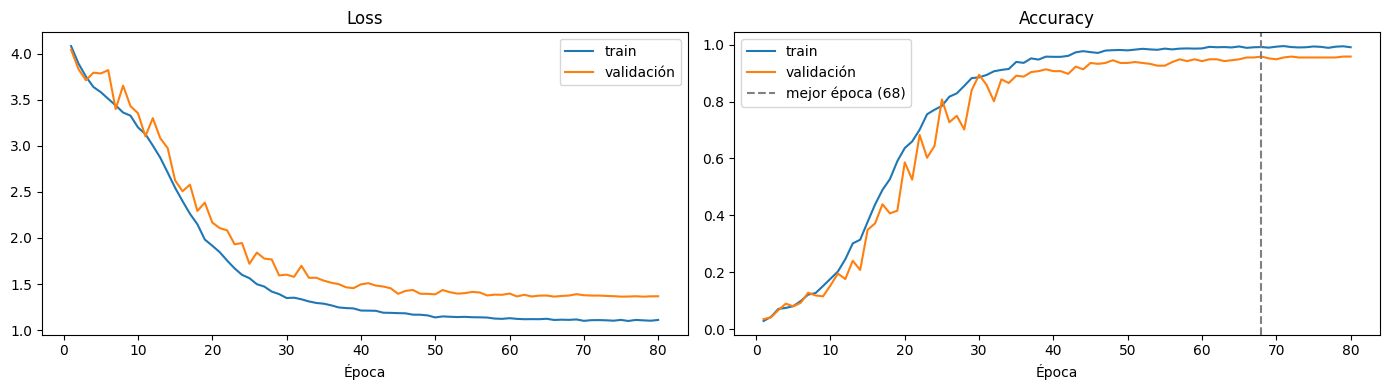

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(df_hist["época"], df_hist["loss_train"], label="train")
axes[0].plot(df_hist["época"], df_hist["loss_val"], label="validación")
axes[0].set_title("Loss"); axes[0].set_xlabel("Época"); axes[0].legend()
axes[1].plot(df_hist["época"], df_hist["acc_train"], label="train")
axes[1].plot(df_hist["época"], df_hist["acc_val"], label="validación")
axes[1].axvline(mejor_ep, color="gray", linestyle="--", label=f"mejor época ({mejor_ep})")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Época"); axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretación de las curvas:** en las primeras épocas el accuracy está cerca del azar (1/43 ≈ 2%; 9% en la época 4), algo esperable en una red entrenada desde cero con augmentation. Después sube rápido (44% en la época 17, 89% en la 30) y se estabiliza alrededor de la época 50. El mejor modelo se obtuvo en la **época 68, con 95,8% de accuracy en validación** (99,2% en train). El early stopping no llegó a activarse: el entrenamiento completó las 80 épocas porque la validación siguió mejorando de a poco hasta el final.

Hasta la época ~30 las curvas de train y validación van juntas. Desde ahí se abre una brecha chica (3-4 puntos de accuracy, y el loss de validación se estanca en ~1,37 mientras el de train sigue bajando a ~1,1). Hay un **sobreajuste leve y controlado**: la regularización (augmentation, dropout, weight decay, label smoothing) evita que la brecha crezca. No hay underfitting: el modelo llega a ~99% en train. Los valores absolutos del loss son altos porque el label smoothing y los pesos por clase impiden que llegue a 0.

Este accuracy mide la **clasificación de las 43 personas del entrenamiento**, pero la app necesita algo distinto: que los embeddings separen **personas nuevas**. Por eso, para comparar experimentos usamos también el **EER sobre el open-set de validación** (personas que la CNN nunca vio).

#### Evaluación en personas nuevas (EER open-set)

In [ ]:
@torch.no_grad()
def emb_cnn(m, imgs_rgb, bs=256):
    """Embeddings L2-normalizados de la CNN para un array de caras RGB uint8."""
    m.eval()
    out = []
    for s in range(0, len(imgs_rgb), bs):
        x = torch.stack([a_tensor(im) for im in imgs_rgb[s:s + bs]]).to(device)
        out.append(m.embedding(x).cpu().numpy())
    return np.vstack(out)

def pares(embs, labs):
    """Similitud coseno de todos los pares: (genuinos = misma persona, impostores = distinta). Adaptado de la clase 4, §6.14.7."""
    sims = embs @ embs.T
    iu = np.triu_indices(len(embs), 1)
    misma = (labs[:, None] == labs[None, :])[iu]
    s = sims[iu]
    return s[misma], s[~misma]

def eer_auc(gen, imp):
    y_true = np.r_[np.ones(len(gen)), np.zeros(len(imp))]
    scores = np.r_[gen, imp]
    fpr, tpr, thr = roc_curve(y_true, scores)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return (fpr[i] + 1 - tpr[i]) / 2, thr[i], roc_auc_score(y_true, scores)

# Open-set de validación: 9 personas nunca vistas + desconocidos de validación
# (a los desconocidos les sumamos 100000 a la etiqueta para que no coincida con ninguna de las 62)
caras_unk_rgb = np.ascontiguousarray(caras_unk[..., ::-1])
imgs_ov = np.concatenate([caras_rgb[m_open_va], caras_unk_rgb[unk_va]])
labs_ov = np.concatenate([y[m_open_va], y_unk[unk_va] + 100000])

gen, imp = pares(emb_cnn(modelo, imgs_ov), labs_ov)
eer_v, thr_v, auc_v = eer_auc(gen, imp)
print(f"Pares genuinos: {len(gen):,} | impostores: {len(imp):,}")
print(f"CNN softmax -> EER open-set val: {eer_v*100:.2f}% | AUC: {auc_v:.4f}")

experimentos = [{
    "experimento": "1. Softmax + pesos por clase + label smoothing",
    "épocas": mejor_ep, "acc val (43 clases)": round(mejor_acc, 3),
    "EER open-set val": round(eer_v, 4), "AUC open-set val": round(auc_v, 4),
}]
torch.save(modelo.state_dict(), f"{BASE}/cnn_softmax.pt")   # resguardo en Drive

Pares genuinos: 17,298 | impostores: 191,683
CNN softmax -> EER open-set val: 24.02% | AUC: 0.8365


 #### Resultado del experimento 1 (softmax)

La CNN con softmax aprende muy bien a clasificar las 43 personas con las que se entrenó (95,8% de accuracy), pero no sirve bien para reconocer personas nuevas: con un EER de 24% y un AUC de 0,84, se equivoca alrededor de 1 de cada 4 veces al comparar dos caras.

La causa es que tiene muy pocas personas para aprender: 43 personas y ~1.450 fotos. Aprende los rasgos de esas 43 en vez de rasgos generales de las caras.

### **Experimento 2: ArcFace loss**

Con softmax, la red aprende a **separar** las 43 clases, pero nada la obliga a que las caras de una misma persona queden **muy juntas**: alcanza con que queden del lado correcto de la frontera. Eso explica que clasifique bien (95,8%) pero tenga un EER de ~24% con personas nuevas.

**ArcFace**  normaliza embeddings y pesos, y suma un margen angular *m* al ángulo con la clase correcta. Para acertar, la red tiene que dejar cada embedding **más cerca de su clase de lo estrictamente necesario**. Así, las clases quedan compactas y separadas por un margen, que es justo lo que sirve para comparar personas nuevas por similitud coseno.

Usamos los valores que se recomienda para datasets chicos: escala **s = 32** y margen **m = 0,3**. Para aislar el efecto de la loss, mantenemos lo demás igual que en el experimento 1 (arquitectura, AdamW, scheduler, pesos por clase, augmentation), salvo el label smoothing, que no usamos porque el margen de ArcFace ya cumple un rol de regularización.

In [ ]:
class ArcFaceHead(nn.Module):
    """Cabeza ArcFace (adaptada de la clase 4, §7.3.5). Con labels aplica el margen; sin labels devuelve s·cos (para predecir)."""
    def __init__(self, dim, n_clases, s=32.0, m=0.3):
        super().__init__()
        self.W = nn.Parameter(torch.empty(n_clases, dim))
        nn.init.xavier_uniform_(self.W)
        self.s, self.m = s, m
        self.cos_m, self.sin_m = math.cos(m), math.sin(m)
        self.th, self.mm = math.cos(math.pi - m), math.sin(math.pi - m) * m

    def forward(self, emb, labels=None):
        cos = F.linear(F.normalize(emb), F.normalize(self.W)).clamp(-1 + 1e-7, 1 - 1e-7)
        if labels is None:
            return self.s * cos
        sin = torch.sqrt(1.0 - cos ** 2)
        phi = cos * self.cos_m - sin * self.sin_m               # cos(θ + m)
        phi = torch.where(cos > self.th, phi, cos - self.mm)    # estabilidad numérica
        onehot = F.one_hot(labels, cos.size(1)).float()
        return self.s * (onehot * phi + (1 - onehot) * cos)

class CNNArcFace(CNNFacial):
    """Misma CNN que el experimento 1; solo cambia la cabeza."""
    def __init__(self, n_clases, dim_emb=128, p_drop=0.3, s=32.0, m=0.3):
        super().__init__(n_clases, dim_emb, p_drop)
        self.clasif = ArcFaceHead(dim_emb, n_clases, s, m)

def entrenar(modelo, criterio, opt, sched, arcface, ckpt, epocas=80, paciencia=15):
    def epoca(dl, train):
        modelo.train(train)
        tl, ac, n = 0.0, 0, 0
        with torch.set_grad_enabled(train):
            for x, t in dl:
                x, t = x.to(device), t.to(device)
                e = modelo.emb(modelo.pool(modelo.features(x)))
                out = modelo.clasif(e, t) if arcface else modelo.clasif(e)
                loss = criterio(out, t)
                if train:
                    opt.zero_grad(); loss.backward(); opt.step()
                pred = (modelo.clasif(e) if arcface else out).argmax(1)   # predicción sin margen
                tl += loss.item() * len(t); ac += (pred == t).sum().item(); n += len(t)
        return tl / n, ac / n

    hist, mejor_acc, mejor_ep, sin_mejora = [], 0.0, 0, 0
    t0 = time.time()
    for ep in range(1, epocas + 1):
        l_tr, a_tr = epoca(dl_tr, True)
        l_va, a_va = epoca(dl_va, False)
        sched.step()
        hist.append({"época": ep, "loss_train": l_tr, "acc_train": a_tr, "loss_val": l_va, "acc_val": a_va})
        if a_va > mejor_acc:
            mejor_acc, mejor_ep, sin_mejora = a_va, ep, 0
            torch.save(modelo.state_dict(), ckpt)
        else:
            sin_mejora += 1
        if ep % 5 == 0 or sin_mejora == 0:
            print(f"Época {ep:3d} | train loss {l_tr:.3f} acc {a_tr:.3f} | val loss {l_va:.3f} acc {a_va:.3f}" + ("  <- mejor" if sin_mejora == 0 else ""))
        if sin_mejora >= paciencia:
            print(f"Early stopping en la época {ep}")
            break
    modelo.load_state_dict(torch.load(ckpt))
    print(f"\nTiempo: {time.time() - t0:.0f} s | mejor accuracy de validación: {mejor_acc:.3f} (época {mejor_ep})")
    return pd.DataFrame(hist), mejor_ep, mejor_acc

def graficar_curvas(df_h, mejor_ep, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for col, ax, nombre in [("loss", axes[0], "Loss"), ("acc", axes[1], "Accuracy")]:
        ax.plot(df_h["época"], df_h[f"{col}_train"], label="train")
        ax.plot(df_h["época"], df_h[f"{col}_val"], label="validación")
        ax.axvline(mejor_ep, color="gray", linestyle="--", label=f"mejor época ({mejor_ep})")
        ax.set_title(f"{nombre} — {titulo}"); ax.set_xlabel("Época"); ax.legend()
    plt.tight_layout(); plt.show()

#### Entrenamiento y curvas de aprendizaje del experimento 2

Época   1 | train loss 14.874 acc 0.032 | val loss 13.883 acc 0.022  <- mejor
Época   3 | train loss 13.432 acc 0.034 | val loss 13.198 acc 0.032  <- mejor
Época   4 | train loss 13.352 acc 0.023 | val loss 13.201 acc 0.042  <- mejor
Época   5 | train loss 13.258 acc 0.049 | val loss 13.187 acc 0.042
Época   6 | train loss 13.223 acc 0.041 | val loss 12.977 acc 0.045  <- mejor
Época  10 | train loss 12.993 acc 0.039 | val loss 12.908 acc 0.058  <- mejor
Época  11 | train loss 12.965 acc 0.040 | val loss 12.704 acc 0.077  <- mejor
Época  13 | train loss 12.797 acc 0.064 | val loss 12.675 acc 0.087  <- mejor
Época  14 | train loss 12.706 acc 0.072 | val loss 12.507 acc 0.096  <- mejor
Época  15 | train loss 12.668 acc 0.073 | val loss 12.612 acc 0.071
Época  17 | train loss 12.601 acc 0.082 | val loss 12.473 acc 0.112  <- mejor
Época  20 | train loss 12.431 acc 0.098 | val loss 12.260 acc 0.099
Época  22 | train loss 12.225 acc 0.118 | val loss 12.478 acc 0.119  <- mejor
Época  23 | trai

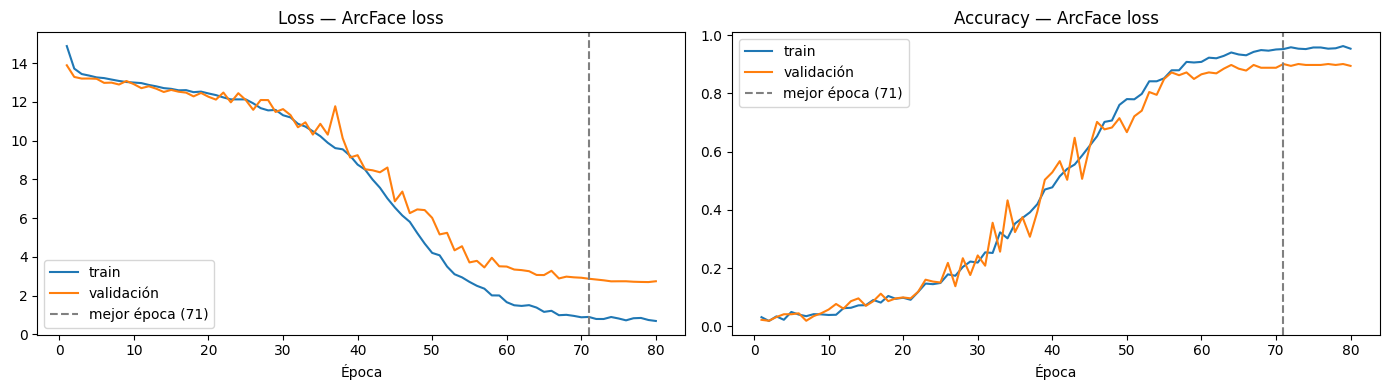

CNN ArcFace -> EER open-set val: 23.47% | AUC: 0.8428


,experimento,épocas,acc val (43 clases),EER open-set val,AUC open-set val
0,1. Softmax + pesos por clase + label smoothing,68,0.958,0.2402,0.8365
1,"2. ArcFace loss (s=32, m=0,3)",71,0.901,0.2347,0.8428


In [ ]:
torch.manual_seed(SEED)
modelo_af = CNNArcFace(N_CLASES, s=32.0, m=0.3).to(device)
criterio_af = nn.CrossEntropyLoss(weight=pesos)       # mismos pesos por clase; sin label smoothing (el margen ya regulariza)
opt_af = torch.optim.AdamW(modelo_af.parameters(), lr=1e-3, weight_decay=5e-4)   # incluye los pesos W de la cabeza
sched_af = torch.optim.lr_scheduler.CosineAnnealingLR(opt_af, T_max=80)

df_hist_af, mejor_ep_af, mejor_acc_af = entrenar(modelo_af, criterio_af, opt_af, sched_af, arcface=True, ckpt="mejor_cnn_arcface.pt")
graficar_curvas(df_hist_af, mejor_ep_af, "ArcFace loss")

gen, imp = pares(emb_cnn(modelo_af, imgs_ov), labs_ov)
eer_v, thr_v, auc_v = eer_auc(gen, imp)
print(f"CNN ArcFace -> EER open-set val: {eer_v*100:.2f}% | AUC: {auc_v:.4f}")

experimentos.append({
    "experimento": "2. ArcFace loss (s=32, m=0,3)",
    "épocas": mejor_ep_af, "acc val (43 clases)": round(mejor_acc_af, 3),
    "EER open-set val": round(eer_v, 4), "AUC open-set val": round(auc_v, 4),
})
torch.save(modelo_af.state_dict(), f"{BASE}/cnn_arcface.pt")
display(pd.DataFrame(experimentos))

**Resultados de los experimentos:** ArcFace loss no mejoró de forma relevante al entrenamiento con softmax. El EER sobre personas nunca vistas fue prácticamente igual (ArcFace loss 23,5% vs softmax 24,0%): una diferencia de medio punto, dentro de la variabilidad entre corridas. En clasificación fue peor: 90,1% de accuracy de validación contra 95,8%. Además, ArcFace sobreajustó más: al final el loss de train bajó a ~0,7 mientras el de validación se estancó en ~2,7, porque el margen angular vuelve la tarea más exigente y, con pocos datos, la red tiende a memorizar.

**Modelo A elegido:** la CNN del **experimento 1 (softmax)**. Su EER es equivalente al de ArcFace loss (la diferencia de 0,5 puntos está dentro de la variabilidad entre corridas), pero clasifica mejor (95,8% vs 90,1%), sobreajusta menos y es más simple.

In [ ]:
modelo_A = modelo          # CNN del experimento 1 (softmax), ya cargada con su mejor checkpoint
modelo_A.eval()
print("Modelo A: CNN softmax | parámetros:", f"{sum(p.numel() for p in modelo_A.parameters()):,}")

Modelo A: CNN softmax | parámetros: 2,392,587


## **Modelo B — ArcFace preentrenado (InsightFace)**

Usamos el modelo como **extractor de embeddings, sin reentrenar**, sobre las mismas caras alineadas y los mismos conjuntos que el Modelo A.

| Característica | Valor |
|---|---|
| Paquete | InsightFace `buffalo_l` |
| Detector | SCRFD-10GF (`det_10g.onnx`), el mismo de la notebook 1 y de la app |
| Reconocedor | **ArcFace con backbone ResNet-50** (`w600k_r50.onnx`) |
| Datos de entrenamiento | **WebFace600K** (subconjunto de WebFace260M: ~600.000 identidades y ~12 M de imágenes de internet) |
| Loss | ArcFace (margen angular aditivo; Deng et al., 2019) |
| Entrada | cara alineada 112×112; el modelo convierte BGR→RGB y normaliza con (x − 127,5) / 127,5 internamente |
| Embedding | **512 dimensiones**, normalizado L2 |
| Licencia | **uso no comercial / investigación** (modelos preentrenados de InsightFace) |

**Limitación a tener en cuenta:** WebFace600K se armó con fotos de personas públicas obtenidas de internet, igual que LFW. Es posible que algunas de nuestras identidades estuvieran en su entrenamiento, por lo que sus resultados pueden ser **optimistas**.

### Cargar el modelo

In [ ]:
FaceAnalysis(name="buffalo_l", providers=["CPUExecutionProvider"])   # descarga buffalo_l si no está
RUTA_B = os.path.expanduser("~/.insightface/models/buffalo_l/w600k_r50.onnx")
modelo_B = get_model(RUTA_B, providers=["CPUExecutionProvider"])
modelo_B.prepare(ctx_id=-1)

grafo = onnx.load(RUTA_B)
n_params_B = sum(int(np.prod(t.dims)) for t in grafo.graph.initializer)
del grafo
tam_B = os.path.getsize(RUTA_B) / 1e6
print(f"Entrada: {modelo_B.input_shape} | salida: {modelo_B.output_shape}")
print(f"Normalización interna: (x - {modelo_B.input_mean}) / {modelo_B.input_std}")
print(f"Parámetros: {n_params_B:,} | tamaño del archivo: {tam_B:.0f} MB")

Entrada: ['None', 3, 112, 112] | salida: [1, 512]
Normalización interna: (x - 127.5) / 127.5
Parámetros: 43,590,976 | tamaño del archivo: 174 MB


### Embeddings de los dos modelos

In [ ]:
def emb_arcface(imgs_bgr, bs=64):
    """Embeddings L2-normalizados de ArcFace (recibe caras alineadas BGR uint8, como en la app)."""
    out = [modelo_B.get_feat(list(imgs_bgr[s:s + bs])) for s in range(0, len(imgs_bgr), bs)]
    e = np.vstack(out).astype(np.float32)
    return e / np.linalg.norm(e, axis=1, keepdims=True)

# Modelo B: se calculan una sola vez y se guardan en Drive (en CPU tarda ~20-25 min)
CACHE_B = f"{BASE}/embeddings_modelo_B.npz"
if os.path.exists(CACHE_B):
    d = np.load(CACHE_B)
    E_B, E_B_unk = d["E"], d["E_unk"]
    print("Embeddings del Modelo B cargados desde Drive")
else:
    t0 = time.time()
    E_B = emb_arcface(caras)
    E_B_unk = emb_arcface(caras_unk)
    np.savez_compressed(CACHE_B, E=E_B, E_unk=E_B_unk)
    print(f"Embeddings del Modelo B calculados en {time.time() - t0:.0f} s y guardados en Drive")

# Modelo A: en GPU tarda segundos
E_A = emb_cnn(modelo_A, caras_rgb)
E_A_unk = emb_cnn(modelo_A, caras_unk_rgb)

print(f"Modelo A: {E_A.shape} + desconocidos {E_A_unk.shape}")
print(f"Modelo B: {E_B.shape} + desconocidos {E_B_unk.shape}")

# Primera comparación, sobre el mismo open-set de validación que usamos en los experimentos
E_ov_B = np.concatenate([E_B[m_open_va], E_B_unk[unk_va]])
gen, imp = pares(E_ov_B, labs_ov)
eer_b, _, auc_b = eer_auc(gen, imp)

In [ ]:
print(f"\nModelo B -> EER open-set val: {eer_b*100:.2f}% | AUC: {auc_b:.4f}   (Modelo A: {experimentos[0]['EER open-set val']*100:.2f}% | {experimentos[0]['AUC open-set val']:.4f})")


Modelo B -> EER open-set val: 0.04% | AUC: 1.0000   (Modelo A: 24.02% | 0.8365)


## **Evaluación**

Los dos modelos se evalúan sobre sus embeddings (normalizados L2), con el mismo protocolo y los mismos conjuntos:


- **Verificación y umbral:** open-set (personas que la CNN nunca vio) + desconocidos. El umbral se calibra en **validación** y las métricas finales se reportan en **test**.
- **Identificación:** galería = train del closed-set; consultas = test del closed-set + desconocidos de test.



### **a) Verificación (¿son la misma persona?)**

Sobre el test del open-set (10 personas) más los desconocidos de test, formamos **todos los pares de la misma persona** (positivos) y **sorteamos la misma cantidad de pares de personas distintas** (negativos), con semilla fija. Como el orden de las imágenes es el mismo para los dos modelos, ambos se evalúan sobre exactamente los mismos pares. Para cada par calculamos la similitud coseno y reportamos curva ROC, AUC, EER y TAR@FAR (FAR = 1e-2 y 1e-3).

Pares positivos: 13,969 | negativos: 13,969


,AUC,EER,TAR@FAR=1e-2,TAR@FAR=1e-3
A — CNN propia,0.889,0.1891,0.3196,0.1100
B — ArcFace,1.000,0.0001,1.0000,0.9999


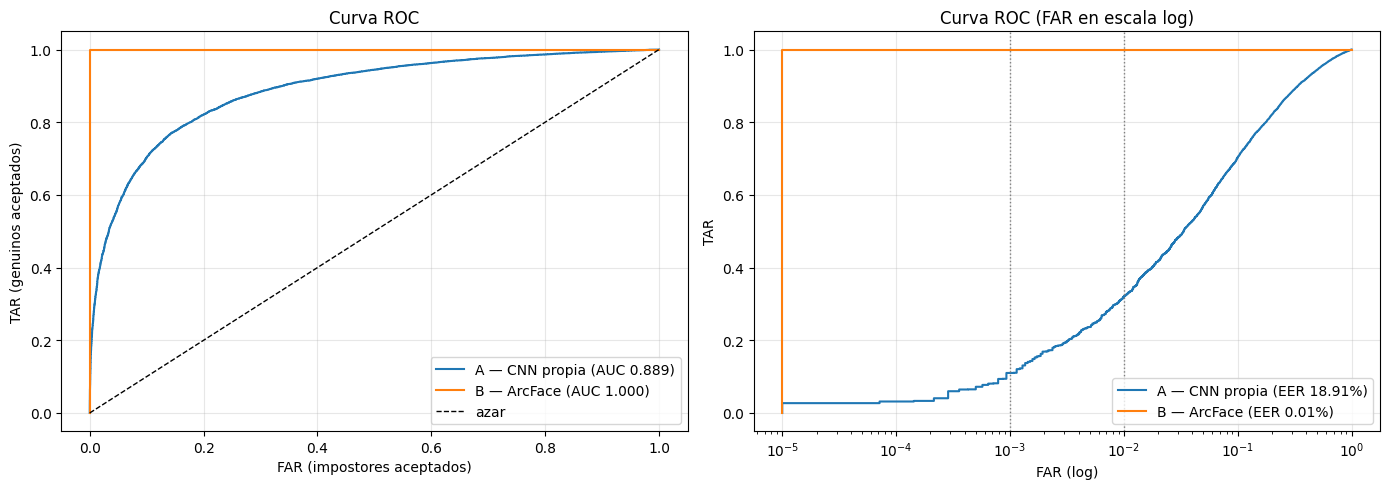

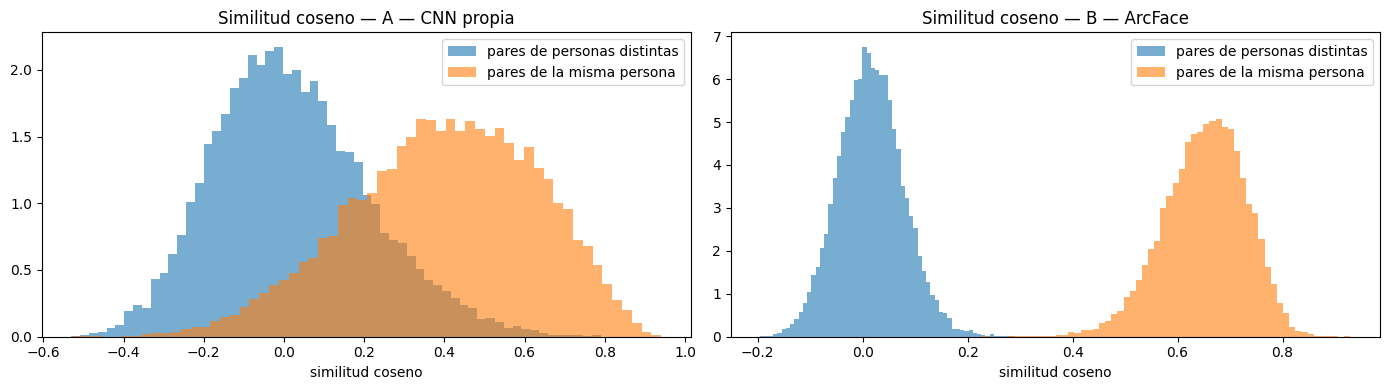

In [ ]:
def pares_balanceados(E, labs, seed=SEED):
    """Todos los pares positivos y la misma cantidad de negativos sorteados (mismos pares para cualquier modelo)."""
    sims = E @ E.T
    iu = np.triu_indices(len(E), 1)
    misma = (labs[:, None] == labs[None, :])[iu]
    s = sims[iu]
    gen, imp = s[misma], s[~misma]
    imp = imp[np.random.RandomState(seed).choice(len(imp), size=len(gen), replace=False)]
    return gen, imp

def metricas_verif(gen, imp):
    y_true = np.r_[np.ones(len(gen)), np.zeros(len(imp))]
    sc = np.r_[gen, imp]
    fpr, tpr, thr = roc_curve(y_true, sc)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    tar = lambda far: tpr[fpr <= far].max()
    return {"AUC": roc_auc_score(y_true, sc), "EER": (fpr[i] + 1 - tpr[i]) / 2,
            "TAR@FAR=1e-2": tar(1e-2), "TAR@FAR=1e-3": tar(1e-3), "fpr": fpr, "tpr": tpr}

# Test del open-set + desconocidos de test
labs_ot = np.concatenate([y[m_open_te], y_unk[unk_te] + 100000])
E_ot = {
    "A — CNN propia": np.concatenate([E_A[m_open_te], E_A_unk[unk_te]]),
    "B — ArcFace": np.concatenate([E_B[m_open_te], E_B_unk[unk_te]]),
}

res_verif, scores_test = {}, {}
for nombre, E in E_ot.items():
    gen, imp = pares_balanceados(E, labs_ot)
    scores_test[nombre] = (gen, imp)
    res_verif[nombre] = metricas_verif(gen, imp)
print(f"Pares positivos: {len(gen):,} | negativos: {len(imp):,}")

tabla_verif = pd.DataFrame({n: {k: v for k, v in r.items() if k not in ("fpr", "tpr")} for n, r in res_verif.items()}).T
display(tabla_verif.round(4))

# Curvas ROC (eje FAR en escala logarítmica, como se reporta en reconocimiento facial)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, r in res_verif.items():
    axes[0].plot(r["fpr"], r["tpr"], label=f"{nombre} (AUC {r['AUC']:.3f})")
    axes[1].semilogx(np.clip(r["fpr"], 1e-5, None), r["tpr"], label=f"{nombre} (EER {r['EER']*100:.2f}%)")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="azar")
axes[0].set_title("Curva ROC"); axes[0].set_xlabel("FAR (impostores aceptados)"); axes[0].set_ylabel("TAR (genuinos aceptados)")
for far in (1e-3, 1e-2):
    axes[1].axvline(far, color="gray", ls=":", lw=1)
axes[1].set_title("Curva ROC (FAR en escala log)"); axes[1].set_xlabel("FAR (log)"); axes[1].set_ylabel("TAR")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Histogramas de similitud: positivos vs. negativos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre, (gen, imp)) in zip(axes, scores_test.items()):
    ax.hist(imp, bins=60, alpha=0.6, density=True, label="pares de personas distintas")
    ax.hist(gen, bins=60, alpha=0.6, density=True, label="pares de la misma persona")
    ax.set_title(f"Similitud coseno — {nombre}"); ax.set_xlabel("similitud coseno"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación de la verificación (test, 13.969 pares positivos y 13.969 negativos):**

| | AUC | EER | TAR@FAR=1e-2 | TAR@FAR=1e-3 |
|---|---|---|---|---|
| A — CNN propia | 0,889 | 18,9% | 32,0% | 11,0% |
| B — ArcFace | 1,000 | 0,01% | 100% | 99,99% |

- **ArcFace separa casi perfectamente** a personas que no estaban en nuestro entrenamiento: en el histograma, los pares de personas distintas se concentran alrededor de 0 (entre −0,2 y 0,25) y los de la misma persona alrededor de 0,65 (entre 0,35 y 0,9). Las dos distribuciones **no se superponen**, así que cualquier umbral en el hueco entre ambas casi no comete errores.
- **La CNN propia separa, pero con mucha superposición:** los pares de personas distintas se centran en ~0 y los de la misma persona en ~0,45, pero ambas distribuciones son anchas y se superponen entre ~0 y ~0,5. Por eso el EER es de casi 19%.
- **La diferencia es mucho más grande en las métricas exigentes:** aunque el AUC de la CNN (0,89) parece aceptable, cuando se exige aceptar muy pocos impostores (FAR = 1 en 1.000, lo que necesitaría una app real) la CNN reconoce solo el **11%** de los pares genuinos y ArcFace casi el **100%**. El AUC resume toda la curva, pero lo que importa en la práctica es la zona de FAR bajo (ROC en escala logarítmica).
- **Estabilidad:** ArcFace da prácticamente lo mismo en validación (EER 0,04%) y en test (0,01%). La CNN varía más (24,0% en validación y 18,9% en test), porque cada conjunto tiene solo 9 o 10 personas nuevas y su resultado depende mucho de cuáles tocan.

### **b) Identificación (¿quién es?)**

Imitamos el uso de la app:

- **Galería:** igual que con `/insert`, se registran pocas imágenes por persona. Usamos **K = 5 imágenes por persona**, sorteadas (semilla fija) del train del closed-set, para las 62 personas. Los dos modelos usan exactamente la misma galería.
- **Consultas:** el test del closed-set (imágenes nuevas de las 62 personas registradas) y, más abajo, los **desconocidos de test** (personas que no están en la galería).
- **Decisión:** se calcula la similitud coseno entre la consulta y cada imagen de la galería. La persona predicha es la de la imagen más parecida (vecino más cercano, 1-NN). Para el Top-5 se ordenan las personas según su mejor similitud.

Primero evaluamos solo las consultas de personas registradas. El rechazo de desconocidos necesita un umbral, así que se evalúa después de calibrarlo (secciones c y d).

In [ ]:
#Galería: K imágenes por persona (imita el /insert de la app)
K_GALERIA = 5
idx_train = np.where(m_gal)[0]                      # train del closed-set (62 personas)

def armar_galeria(k, seed=SEED):
    '''Máscara con k imágenes sorteadas por persona (semilla fija; un k muy grande toma todas).'''
    rng = np.random.RandomState(seed)
    sel = []
    for i in np.unique(y[idx_train]):
        cand = idx_train[y[idx_train] == i]
        sel.extend(rng.choice(cand, size=min(k, len(cand)), replace=False))
    m = np.zeros(len(y), dtype=bool)
    m[sel] = True
    return m

m_gal5 = armar_galeria(K_GALERIA)
nombres = dict(zip(df["label"], df["persona"]))     # número de identidad -> nombre

def identificar(E_q, E_g, y_g):
    '''Por consulta: mejor similitud coseno con cada persona de la galería (n_consultas x n_personas),
    persona predicha (la del vecino más parecido, 1-NN) y las 5 personas más parecidas.'''
    ids_g = np.unique(y_g)
    sim = E_q @ E_g.T
    S = np.stack([sim[:, y_g == i].max(axis=1) for i in ids_g], axis=1)
    orden = np.argsort(-S, axis=1)
    return S, ids_g[orden[:, 0]], ids_g[orden[:, :5]]

EMB = {"A — CNN propia": (E_A, E_A_unk), "B — ArcFace": (E_B, E_B_unk)}
y_q = y[m_cons]
vistos = np.isin(y_q, ids_cnn)      # True si la persona estaba entre las 43 que la CNN vio al entrenar

res_ident, S_ident, pred_ident = {}, {}, {}
for nombre, (E, _) in EMB.items():
    S, pred, top5 = identificar(E[m_cons], E[m_gal5], y[m_gal5])
    p, r, f1, _ = precision_recall_fscore_support(y_q, pred, average="macro", zero_division=0)
    res_ident[nombre] = {
        "Top-1": (pred == y_q).mean(),
        "Top-5": (top5 == y_q[:, None]).any(axis=1).mean(),
        "Precisión (macro)": p, "Recall (macro)": r, "F1 (macro)": f1,
        "Top-1, personas que la CNN vio": (pred == y_q)[vistos].mean(),
        "Top-1, personas que la CNN no vio": (pred == y_q)[~vistos].mean(),
    }
    S_ident[nombre], pred_ident[nombre] = S, pred

print(f"Galería: {m_gal5.sum()} imágenes ({K_GALERIA} por persona, {len(np.unique(y[m_gal5]))} personas) | "
      f"consultas: {m_cons.sum()} imágenes ({vistos.sum()} de personas que la CNN vio, {(~vistos).sum()} de personas que no)")
display(pd.DataFrame(res_ident).T.round(4))

Galería: 310 imágenes (5 por persona, 62 personas) | consultas: 446 imágenes (313 de personas que la CNN vio, 133 de personas que no)


,Top-1,Top-5,Precisión (macro),Recall (macro),F1 (macro),"Top-1, personas que la CNN vio","Top-1, personas que la CNN no vio"
A — CNN propia,0.8027,0.9619,0.7646,0.7925,0.7587,0.9233,0.5188
B — ArcFace,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000



- Con personas que no vio al entrenar, el acierto baja al 52%, contra el 92% con personas que sí vio. Es la misma conclusión de antes (no generaliza bien a personas nuevas), pero ahora medida en identificación.
- ArcFace identifica a todas bien, sin distinción entre personas vistas o no.

- El 92% en personas vistas es optimista: la CNN entrenó con esas personas, y con algunas de las fotos que ahora están en la galería.
El 100% de ArcFace también puede ser optimista, porque WebFace600K puede incluir a varias de estas personas públicas.

**Interpretación de la identificación (galería de 5 imágenes por persona, 446 consultas de test de 62 personas):**

- **ArcFace identifica a todas las consultas correctamente** (Top-1 = Top-5 = 100%), también a las personas que la CNN no vio al entrenar. Este resultado puede ser optimista: WebFace600K se armó con fotos de personas públicas de internet y es posible que incluya a algunas de nuestras personas.
- **La CNN propia acierta el 80,3% en Top-1 y el 96,2% en Top-5** (F1 macro 75,9%). Hay un fuerte contraste según la persona: con las 43 personas que vio al entrenar acierta el 92,3%, pero con las 19 que nunca vio solo el **51,9%**. Es la misma limitación que vimos en la verificación: la red aprendió a distinguir a las personas de su entrenamiento, pero sus embeddings no generalizan bien a caras nuevas. Además, el 92,3% es optimista, porque algunas imágenes de la galería son del propio entrenamiento.

¿Cuántas imágenes hay que registrar por persona? Repetimos la identificación variando el tamaño de la galería (siempre las mismas consultas)

In [ ]:
filas = []
for k in [1, 3, 5, 10, 10**6]:
    mg = armar_galeria(k)
    fila = {"imágenes por persona": f"todas (≈{mg.sum() / 62:.0f})" if k == 10**6 else k}
    for nombre, (E, _) in EMB.items():
        _, pred, _ = identificar(E[m_cons], E[mg], y[mg])
        fila[f"Top-1 {nombre}"] = round((pred == y_q).mean(), 4)
    filas.append(fila)
display(pd.DataFrame(filas))

,imágenes por persona,Top-1 A — CNN propia,Top-1 B — ArcFace
0,1,0.7556,1.0
1,3,0.7713,1.0
2,5,0.8027,1.0
3,10,0.8274,1.0
4,todas (≈34),0.8744,1.0


**Efecto del tamaño de la galería:** la CNN propia mejora de forma gradual a medida que se registran más imágenes por persona: pasa de 75,6% con una sola imagen a 87,4% con todas (~34 por persona). La mejora es de ~12 puntos y se va achicando (de 5 a 10 imágenes suma ~2,5 puntos).

 **ArcFace identifica al 100% de las consultas incluso con una sola imagen por persona**, es decir, sus embeddings son tan consistentes que alcanza con registrar una foto. Para la app esto es una ventaja práctica: con ArcFace el `/insert` no necesita muchas fotos por persona. Usamos K = 5 como valor intermedio, razonable para una galería real.

#### Matriz de confusión (personas con más consultas)

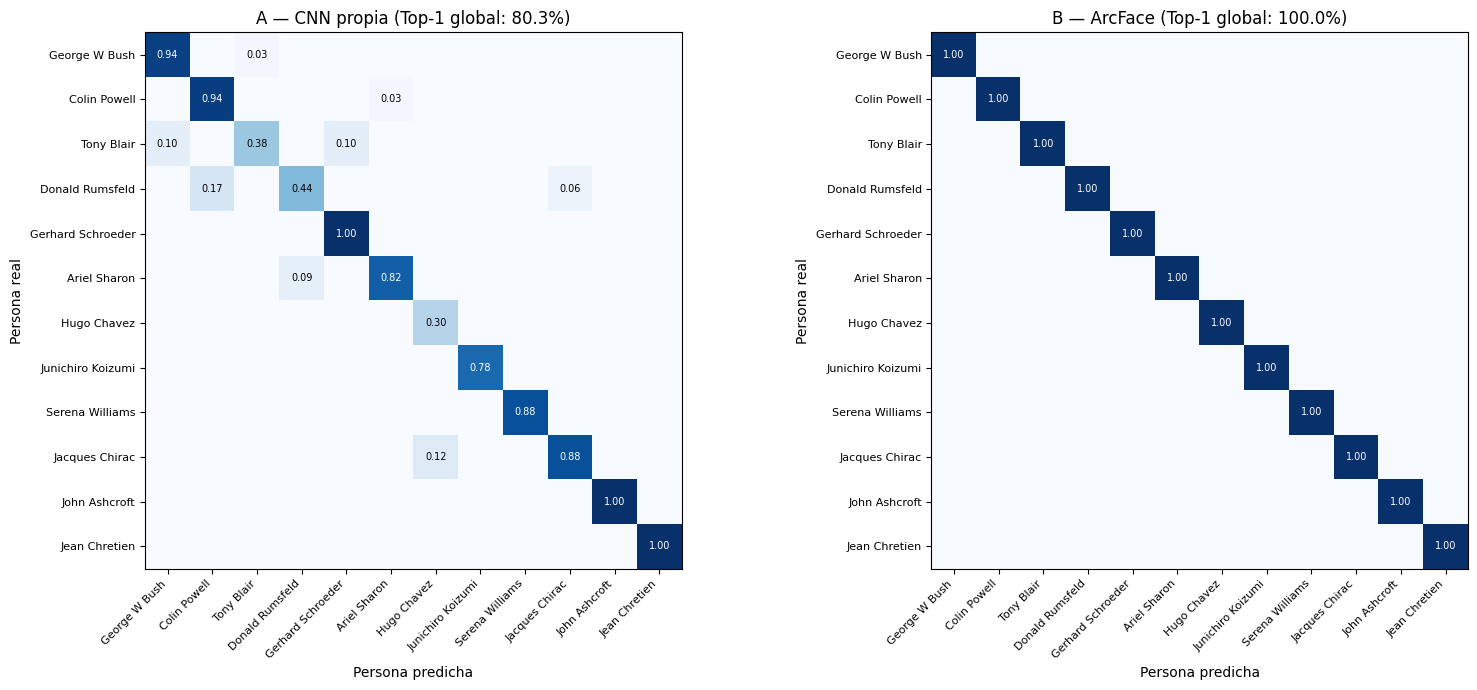


A — CNN propia: 88 errores de 446 consultas. Pares más confundidos:


,real,predicha,veces
0,Hugo Chavez,Alejandro Toledo,6
1,Donald Rumsfeld,Colin Powell,3
2,Vicente Fox,Saddam Hussein,3
3,Donald Rumsfeld,Mahmoud Abbas,2
4,George W Bush,Tony Blair,2
5,Tony Blair,Gerhard Schroeder,2



B — ArcFace: 0 errores de 446 consultas. Pares más confundidos:


,real,predicha,veces


In [ ]:
def graficar_confusion(y_true, y_pred, ids, titulo, ax):
    '''Matriz de confusión (fracción de las consultas de cada persona) para las identidades 'ids'.'''
    cm = confusion_matrix(y_true, y_pred, labels=ids).astype(float)
    total = np.array([(y_true == i).sum() for i in ids], dtype=float)
    cm = cm / np.clip(total[:, None], 1, None)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    etiquetas = [nombres[i] for i in ids]
    ax.set_xticks(range(len(ids))); ax.set_xticklabels(etiquetas, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(ids))); ax.set_yticklabels(etiquetas, fontsize=8)
    for i in range(len(ids)):
        for j in range(len(ids)):
            if cm[i, j] > 0:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xlabel("Persona predicha"); ax.set_ylabel("Persona real"); ax.set_title(titulo)

ids_mostrar = pd.Series(y_q).value_counts().index[:12].tolist()      # las 12 con más consultas

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, nombre in zip(axes, EMB):
    graficar_confusion(y_q, pred_ident[nombre], ids_mostrar,
                       f"{nombre} (Top-1 global: {res_ident[nombre]['Top-1'] * 100:.1f}%)", ax)
plt.tight_layout(); plt.show()

def confundidas(y_true, y_pred, n=6):
    '''Pares (persona real -> persona predicha) con más errores.'''
    err = pd.DataFrame({"real": y_true, "predicha": y_pred})
    err = err[err["real"] != err["predicha"]]
    t = err.value_counts().head(n).reset_index(name="veces")
    t["real"] = t["real"].map(nombres); t["predicha"] = t["predicha"].map(nombres)
    return t

for nombre in EMB:
    n_err = int((pred_ident[nombre] != y_q).sum())
    print(f"\n{nombre}: {n_err} errores de {len(y_q)} consultas. Pares más confundidos:")
    display(confundidas(y_q, pred_ident[nombre]))

**Interpretación de la matriz de confusión:** ArcFace no comete ningún error en las 446 consultas, por eso su diagonal es perfecta y no hay pares confundidos. La CNN propia comete 88 errores (19,7%) y el rendimiento es muy desparejo según la persona: reconoce bien a Schroeder, Ashcroft y Chrétien (100%) y a Bush y Powell (94%), pero falla mucho con Hugo Chávez (30% de aciertos), Tony Blair (38%) y Donald Rumsfeld (44%). Los pares más confundidos son Hugo Chávez con Alejandro Toledo (6 veces), Rumsfeld con Powell (3) y Vicente Fox con Saddam Hussein (3). La CNN, con solo 43 personas de entrenamiento, no aprendió rasgos faciales suficientemente finos y confunde a personas con apariencia general parecida (peinado, edad, vestimenta, pose, iluminación); en la sección de análisis de errores revisamos imágenes concretas para contrastar esta hipótesis.

#### Similitud coseno entre identidades

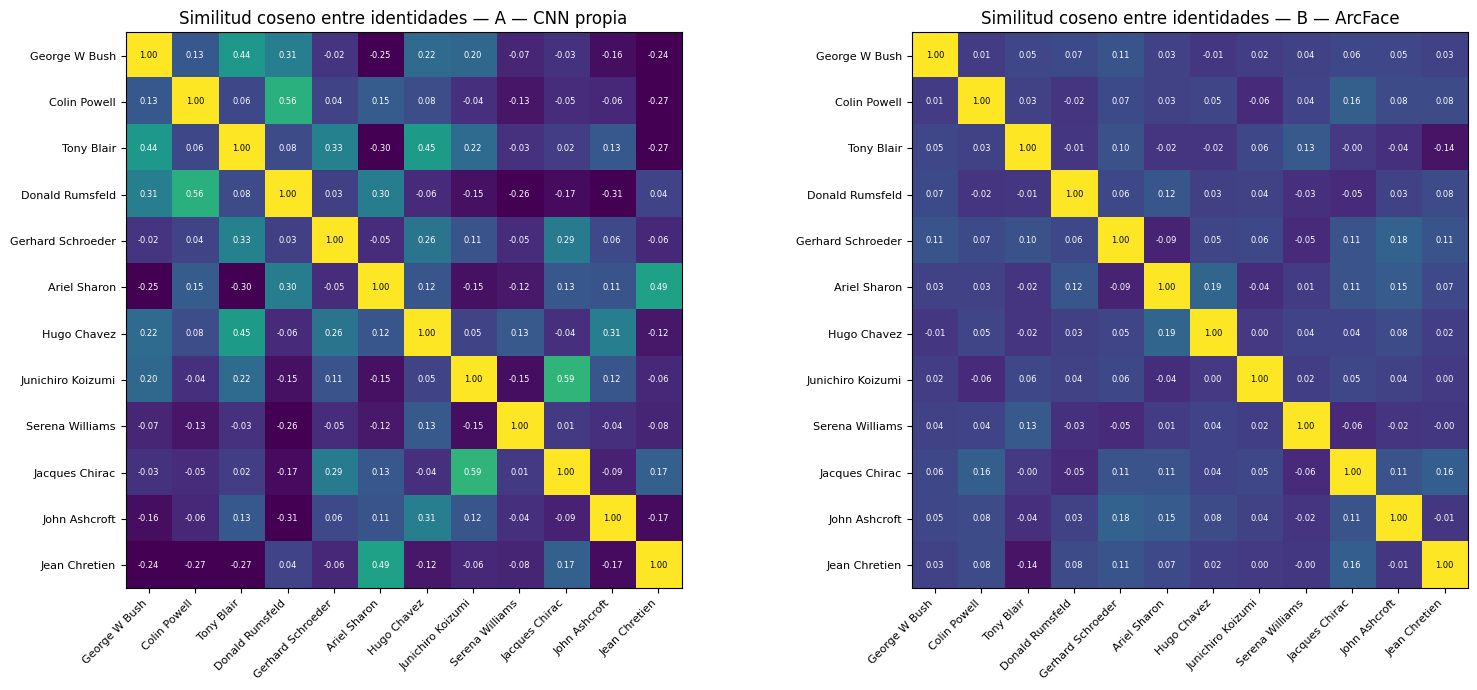

In [ ]:
def heatmap_similitud(E, labs, ids, titulo, ax):
    medias = np.stack([E[labs == i].mean(axis=0) for i in ids])
    medias /= np.linalg.norm(medias, axis=1, keepdims=True)
    sim = medias @ medias.T
    ax.imshow(sim, cmap="viridis", vmin=-0.2, vmax=1)
    etiquetas = [nombres[i] for i in ids]
    ax.set_xticks(range(len(ids))); ax.set_xticklabels(etiquetas, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(ids))); ax.set_yticklabels(etiquetas, fontsize=8)
    for i in range(len(ids)):
        for j in range(len(ids)):
            ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if sim[i, j] < 0.6 else "black")
    ax.set_title(titulo)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (nombre, (E, _)) in zip(axes, EMB.items()):
    heatmap_similitud(E[m_cons], y_q, ids_mostrar, f"Similitud coseno entre identidades — {nombre}", ax)
plt.tight_layout(); plt.show()

- ArcFace (derecha): casi todo fuera de la diagonal es oscuro, con valores entre −0,14 y 0,19. Las personas quedan bien separadas entre sí.
- CNN propia (izquierda): hay varios valores altos, que son personas que el modelo ve parecidas:
Koizumi y Chirac: 0,59
Powell y Rumsfeld: 0,56
Sharon y Chrétien: 0,49
Blair y Chávez: 0,45
Bush y Blair: 0,44

Esto coincide con la matriz de confusión: Powell y Rumsfeld se confunden entre sí, y Bush con Blair también aparece en los errores.

### **c) Elección del umbral**

La app decide `unknown` comparando la similitud coseno con `SIMILARITY_THRESHOLD`: si la mejor similitud es menor, la persona no se reconoce. Un umbral alto rechaza más (menos falsos positivos, más falsos negativos) y uno bajo hace lo contrario:

- **FAR** (False Accept Rate): proporción de pares de personas **distintas** que se aceptan como la misma persona.
- **FRR** (False Reject Rate): proporción de pares de la **misma** persona que se rechazan.

Para no calibrar sobre los mismos datos con los que reportamos, **elegimos el umbral con los pares de validación** (open-set val + desconocidos de val) y **medimos FAR y FRR con los pares de test**. Probamos tres criterios: el punto **EER** (FAR = FRR) y el umbral que da **FAR ≤ 1e-2** y **FAR ≤ 1e-3**. Acá se usan todos los pares (no los balanceados de la verificación), porque FAR y FRR son tasas que no dependen de la proporción de pares positivos y negativos.

,modelo,criterio,umbral τ,FAR val,FRR val,FAR test,FRR test
0,A — CNN propia,EER,0.190,0.2405,0.2401,0.1848,0.1934
1,A — CNN propia,FAR ≤ 1e-2,0.554,0.0100,0.7916,0.0075,0.7235
2,A — CNN propia,FAR ≤ 1e-3,0.704,0.0010,0.9367,0.0007,0.9122
3,B — ArcFace,EER,0.296,0.0004,0.0003,0.0000,0.0006
4,B — ArcFace,FAR ≤ 1e-2,0.190,0.0100,0.0000,0.0053,0.0000
5,B — ArcFace,FAR ≤ 1e-3,0.275,0.0010,0.0001,0.0002,0.0001


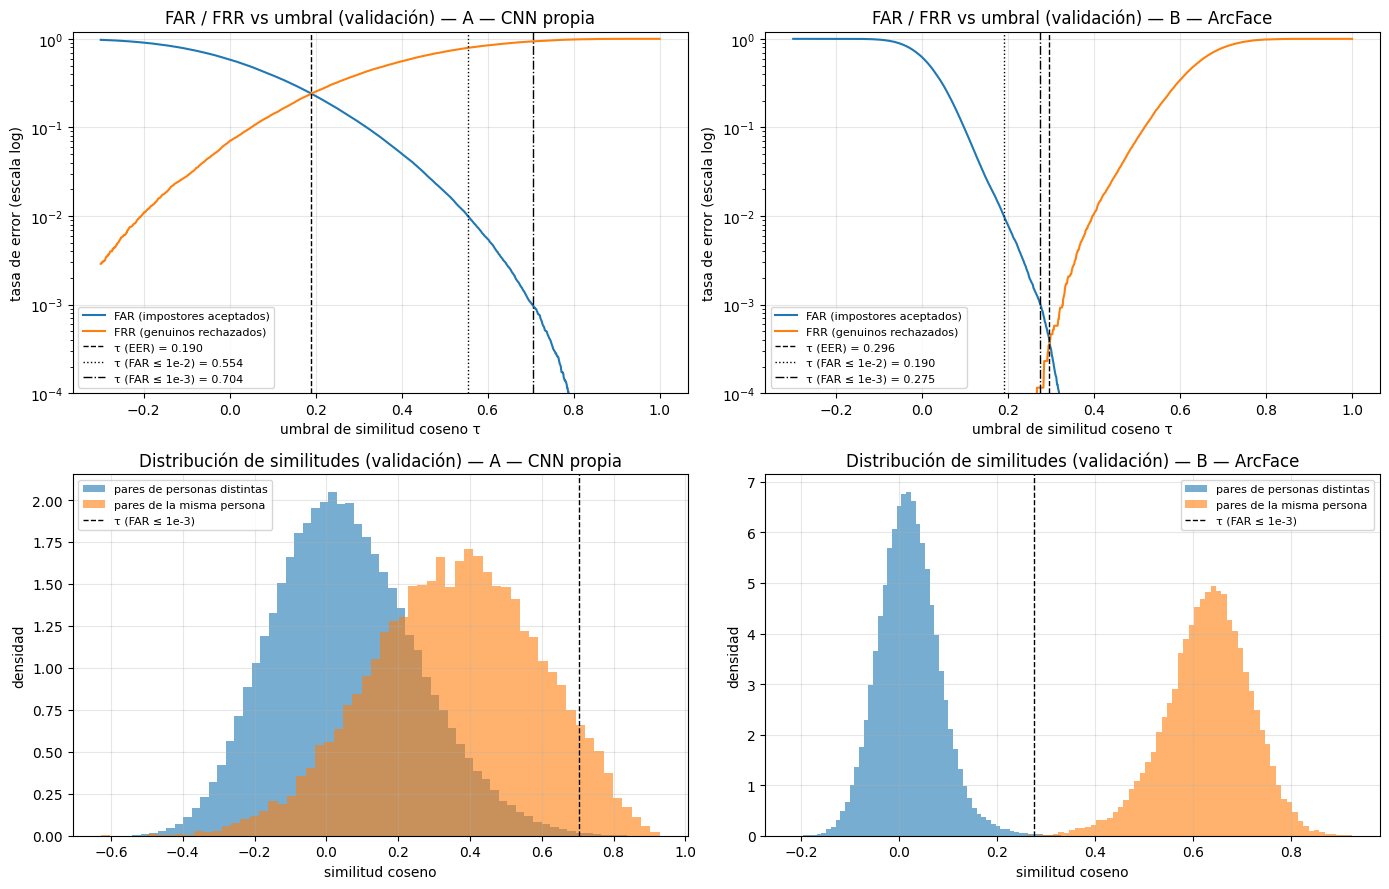

In [ ]:
def umbral_para_tasa(negativos, tasa):
    '''Menor umbral que acepta como mucho 'tasa' de los puntajes negativos (impostores o desconocidos).'''
    k = max(int(np.floor(tasa * len(negativos))), 1)
    return float(np.sort(negativos)[::-1][k - 1])

def curva_far_frr(gen, imp, taus):
    imp_s, gen_s = np.sort(imp), np.sort(gen)
    far = 1 - np.searchsorted(imp_s, taus, side="left") / len(imp_s)     # impostores aceptados (sim >= tau)
    frr = np.searchsorted(gen_s, taus, side="left") / len(gen_s)         # genuinos rechazados (sim < tau)
    return far, frr

taus = np.linspace(-0.3, 1.0, 1301)
UMBRALES, calib, filas = {}, {}, []
for nombre, (E, Eu) in EMB.items():
    gen_v, imp_v = pares(np.concatenate([E[m_open_va], Eu[unk_va]]), labs_ov)      # validación
    gen_t, imp_t = pares(np.concatenate([E[m_open_te], Eu[unk_te]]), labs_ot)      # test
    far_v, frr_v = curva_far_frr(gen_v, imp_v, taus)
    UMBRALES[nombre] = {
        "EER": float(taus[np.argmin(np.abs(far_v - frr_v))]),
        "FAR ≤ 1e-2": umbral_para_tasa(imp_v, 1e-2),
        "FAR ≤ 1e-3": umbral_para_tasa(imp_v, 1e-3),
    }
    calib[nombre] = dict(gen_v=gen_v, imp_v=imp_v, far=far_v, frr=frr_v)
    for crit, tau in UMBRALES[nombre].items():
        filas.append({"modelo": nombre, "criterio": crit, "umbral τ": round(tau, 3),
                      "FAR val": (imp_v >= tau).mean(), "FRR val": (gen_v < tau).mean(),
                      "FAR test": (imp_t >= tau).mean(), "FRR test": (gen_t < tau).mean()})
tabla_umbral = pd.DataFrame(filas)
display(tabla_umbral.round(4))

# FAR y FRR en función del umbral (validación) y distribución de similitudes con el umbral marcado
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, (nombre, c) in enumerate(calib.items()):
    ax = axes[0, col]
    ax.plot(taus, np.clip(c["far"], 1e-5, None), label="FAR (impostores aceptados)")
    ax.plot(taus, np.clip(c["frr"], 1e-5, None), label="FRR (genuinos rechazados)")
    for (crit, tau), ls in zip(UMBRALES[nombre].items(), ["--", ":", "-."]):
        ax.axvline(tau, ls=ls, color="black", lw=1, label=f"τ ({crit}) = {tau:.3f}")
    ax.set_yscale("log"); ax.set_ylim(1e-4, 1.2)
    ax.set_xlabel("umbral de similitud coseno τ"); ax.set_ylabel("tasa de error (escala log)")
    ax.set_title(f"FAR / FRR vs umbral (validación) — {nombre}"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax = axes[1, col]
    ax.hist(c["imp_v"], bins=60, alpha=0.6, density=True, label="pares de personas distintas")
    ax.hist(c["gen_v"], bins=60, alpha=0.6, density=True, label="pares de la misma persona")
    ax.axvline(UMBRALES[nombre]["FAR ≤ 1e-3"], ls="--", color="black", lw=1, label="τ (FAR ≤ 1e-3)")
    ax.set_xlabel("similitud coseno"); ax.set_ylabel("densidad")
    ax.set_title(f"Distribución de similitudes (validación) — {nombre}"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

CRITERIO = "FAR ≤ 1e-3"       # criterio con el que se hacen los análisis siguientes; se decide en la sección 3.4

**Interpretación del umbral (calibrado en validación, medido en test):**

| Modelo | Criterio | τ | FAR test | FRR test |
|---|---|---|---|---|
| A — CNN propia | EER | 0,190 | 18,5% | 19,3% |
| A — CNN propia | FAR ≤ 1e-2 | 0,554 | 0,75% | 72,4% |
| A — CNN propia | FAR ≤ 1e-3 | 0,704 | 0,07% | 91,2% |
| B — ArcFace | EER | 0,296 | 0,00% | 0,06% |
| B — ArcFace | FAR ≤ 1e-2 | 0,190 | 0,53% | 0,00% |
| B — ArcFace | FAR ≤ 1e-3 | 0,275 | 0,02% | 0,01% |

- **ArcFace:** las distribuciones de similitud no se superponen, así que cualquier umbral entre ~0,19 y ~0,30 da errores prácticamente nulos en validación y en test. Que los tres criterios caigan en un rango tan estrecho y con errores tan bajos da margen de seguridad para elegir el umbral.
- **CNN propia:** al superponerse las distribuciones, cada criterio implica sacrificar algo. Con el umbral del EER (0,19) se equivoca cerca del 19% en cada sentido. Para exigir pocos falsos positivos (FAR ≤ 1e-3) hay que subir τ a 0,70, y entonces rechaza el 91% de los pares de la misma persona: no sería utilizable en la app.
- **Generalización del umbral:** los errores medidos en test son parecidos o menores que los de validación, así que el umbral calibrado no está sobreajustado.

#### Rechazo de desconocidos (identificación open-set)

Simulamos el uso real de la app: cada consulta se compara con toda la galería (5 imágenes por persona) y se acepta solo si su mejor similitud supera el umbral τ. Usamos 446 consultas de test de personas registradas y 201 de personas desconocidas, y medimos qué parte de los conocidos se identifica bien y qué parte de los desconocidos se rechaza. Además de los umbrales por pares de la sección anterior, calibramos umbrales directamente con la tasa de desconocidos aceptados (**FPIR**, *false positive identification rate*) en validación: FPIR ≤ 5% y ≤ 1%.

Consultas de test: 446 conocidas y 201 desconocidas


,modelo,criterio,τ,val: id. correcta,val: FPIR,test: id. correcta,test: id. errónea,test: conocidos rechazados,test: desconocidos rechazados,test: desconocidos aceptados (FPIR)
0,A — CNN propia,EER,0.190,0.785,1.000,0.803,0.197,0.000,0.000,1.000
1,A — CNN propia,FAR ≤ 1e-2,0.554,0.760,0.805,0.787,0.159,0.054,0.179,0.821
2,A — CNN propia,FAR ≤ 1e-3,0.704,0.666,0.272,0.664,0.047,0.289,0.736,0.264
3,A — CNN propia,FPIR ≤ 5%,0.793,0.513,0.046,0.527,0.009,0.464,0.940,0.060
4,A — CNN propia,FPIR ≤ 1%,0.969,0.000,0.005,0.000,0.000,1.000,1.000,0.000
5,B — ArcFace,EER,0.296,1.000,0.015,1.000,0.000,0.000,0.985,0.015
6,B — ArcFace,FAR ≤ 1e-2,0.190,1.000,0.508,1.000,0.000,0.000,0.493,0.507
7,B — ArcFace,FAR ≤ 1e-3,0.275,1.000,0.036,1.000,0.000,0.000,0.950,0.050
8,B — ArcFace,FPIR ≤ 5%,0.274,1.000,0.046,1.000,0.000,0.000,0.950,0.050
9,B — ArcFace,FPIR ≤ 1%,0.328,1.000,0.005,1.000,0.000,0.000,0.995,0.005


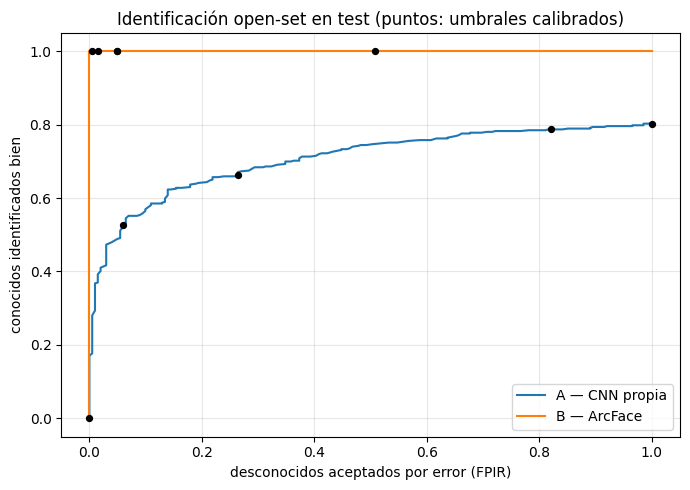

In [ ]:
m_cons_val = ok & (df["split_closed"] == "val").values

def mejor_puntaje(E_q, E):
    S, pred, _ = identificar(E_q, E[m_gal5], y[m_gal5])
    return S.max(axis=1), pred

def metricas_open_set(s_k, pred_k, t_k, s_u, tau):
    acepta = s_k >= tau
    return {"id. correcta": (acepta & (pred_k == t_k)).mean(),
            "id. errónea": (acepta & (pred_k != t_k)).mean(),
            "conocidos rechazados": (~acepta).mean(),
            "desconocidos rechazados": (s_u < tau).mean(),
            "desconocidos aceptados (FPIR)": (s_u >= tau).mean()}

sc = {}
for nombre, (E, Eu) in EMB.items():
    s_kv, p_kv = mejor_puntaje(E[m_cons_val], E);   s_uv, _ = mejor_puntaje(Eu[unk_va], E)
    s_kt, p_kt = mejor_puntaje(E[m_cons], E);       s_ut, _ = mejor_puntaje(Eu[unk_te], E)
    sc[nombre] = {"val": (s_kv, p_kv, y[m_cons_val], s_uv), "test": (s_kt, p_kt, y[m_cons], s_ut)}
    UMBRALES[nombre]["FPIR ≤ 5%"] = umbral_para_tasa(s_uv, 0.05)      # calibrados con desconocidos de validación
    UMBRALES[nombre]["FPIR ≤ 1%"] = umbral_para_tasa(s_uv, 0.01)

filas, RES_OPEN = [], {n: {} for n in EMB}
for nombre in EMB:
    for crit, tau in UMBRALES[nombre].items():
        mv = metricas_open_set(*sc[nombre]["val"], tau)
        mt = metricas_open_set(*sc[nombre]["test"], tau)
        RES_OPEN[nombre][crit] = mt
        filas.append({"modelo": nombre, "criterio": crit, "τ": round(tau, 3),
                      "val: id. correcta": mv["id. correcta"], "val: FPIR": mv["desconocidos aceptados (FPIR)"],
                      **{f"test: {k}": v for k, v in mt.items()}})
tabla_open = pd.DataFrame(filas)
print(f"Consultas de test: {len(sc['B — ArcFace']['test'][0])} conocidas y {len(sc['B — ArcFace']['test'][3])} desconocidas")
display(tabla_open.round(3))

# Compromiso entre reconocer bien a los registrados y aceptar desconocidos (test), variando τ
taus_id = np.linspace(-0.3, 1.0, 651)
fig, ax = plt.subplots(figsize=(7, 5))
for nombre in EMB:
    s_k, p_k, t_k, s_u = sc[nombre]["test"]
    ax.plot([(s_u >= t).mean() for t in taus_id], [((s_k >= t) & (p_k == t_k)).mean() for t in taus_id], label=nombre)
    for crit, tau in UMBRALES[nombre].items():
        ax.scatter(RES_OPEN[nombre][crit]["desconocidos aceptados (FPIR)"], RES_OPEN[nombre][crit]["id. correcta"],
                   color="black", s=18, zorder=3)
ax.set_xlabel("desconocidos aceptados por error (FPIR)"); ax.set_ylabel("conocidos identificados bien")
ax.set_title("Identificación open-set en test (puntos: umbrales calibrados)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación del rechazo de desconocidos:**

- **El FAR por par no se traslada directo a la app.** Con ArcFace, el umbral que da FAR ≤ 1e-2 por par (τ = 0,19) acepta como conocido al 50,7% de los desconocidos, porque cada consulta se compara contra toda la galería y se queda con la mejor similitud. Por eso calibramos también umbrales directamente sobre la identificación (FPIR).
- **ArcFace:** con τ = 0,328 (FPIR ≤ 1% en validación) identifica correctamente al 100% de las personas registradas, no comete errores de identificación y rechaza al 99,5% de los desconocidos. Con τ = 0,275 (FAR ≤ 1e-3 por par) rechaza al 95% de los desconocidos, también sin perder ninguna persona registrada. En el gráfico, su curva queda pegada a la esquina superior izquierda: reconoce a todos los conocidos y casi no acepta desconocidos.
- **CNN propia:** no logra un buen compromiso. Con τ = 0,704 identifica bien al 66,4% de los conocidos y rechaza al 73,6% de los desconocidos. Para rechazar al 94% de los desconocidos (τ = 0,793) solo identifica bien al 52,7% de los conocidos. Con el umbral del 1% de FPIR (τ = 0,969) rechaza a todas las consultas, incluso a las de personas registradas.
- **Estabilidad:** los valores de FPIR de test son coherentes con los de validación (por ejemplo, 0,5% en ambos con ArcFace a FPIR ≤ 1%). Como el umbral de 1% se calibró con 195 desconocidos, su precisión es limitada.

### **d) Clustering de embeddings**

Proyectamos con **t-SNE** (distancia coseno) los embeddings de test de cada modelo, lado a lado y coloreados por identidad. Usamos el **open-set de test: 10 personas que la CNN nunca vio al entrenar**, que es la situación real de la app (reconocer personas registradas después del entrenamiento). Para cuantificar la separación calculamos:

- **Silhouette** con las identidades reales y distancia coseno (−1 a 1; más alto = identidades más compactas y separadas).
- **K-Means** con K = 10 sobre los embeddings, y su concordancia con las identidades reales: **ARI** y **NMI** (0 = azar, 1 = coincidencia perfecta).

t-SNE solo sirve para visualizar; las métricas se calculan sobre los embeddings originales.

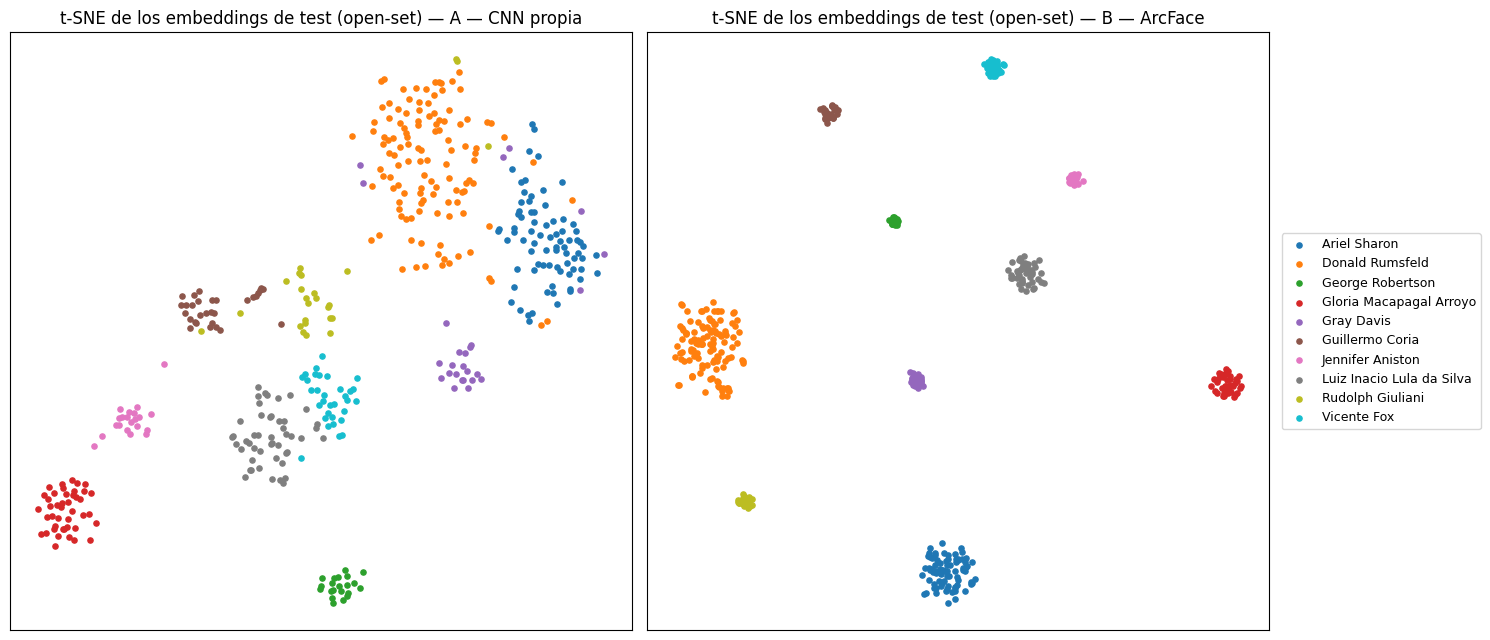

442 imágenes de 10 personas que la CNN no vio


,Silhouette (identidades reales),ARI (K-Means),NMI (K-Means)
A — CNN propia,0.259,0.581,0.777
B — ArcFace,0.607,1.000,1.000


In [ ]:
X_ids = y[m_open_te]
k_cl = len(np.unique(X_ids))
res_clust = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
cmap = plt.get_cmap("tab10")
for ax, (nombre, (E, _)) in zip(axes, EMB.items()):
    X = E[m_open_te]
    km = KMeans(n_clusters=k_cl, n_init=10, random_state=SEED).fit(X)
    res_clust[nombre] = {"Silhouette (identidades reales)": silhouette_score(X, X_ids, metric="cosine"),
                         "ARI (K-Means)": adjusted_rand_score(X_ids, km.labels_),
                         "NMI (K-Means)": normalized_mutual_info_score(X_ids, km.labels_)}
    p2 = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=SEED).fit_transform(X)
    for j, i in enumerate(np.unique(X_ids)):
        ax.scatter(*p2[X_ids == i].T, s=14, color=cmap(j), label=nombres[i])
    ax.set_title(f"t-SNE de los embeddings de test (open-set) — {nombre}"); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout(); plt.show()
print(f"{len(X_ids)} imágenes de {k_cl} personas que la CNN no vio")
display(pd.DataFrame(res_clust).T.round(3))

**Interpretación del clustering (open-set de test: 442 imágenes de 10 personas que la CNN nunca vio):**

| | Silhouette | ARI | NMI |
|---|---|---|---|
| A — CNN propia | 0,259 | 0,581 | 0,777 |
| B — ArcFace | 0,607 | 1,000 | 1,000 |

- **ArcFace** forma 10 grupos compactos y bien separados, uno por persona. K-Means, sin usar las etiquetas, recupera exactamente la partición real (ARI = NMI = 1), y el silhouette (0,61) es el doble que el de la CNN.
- **La CNN propia** también agrupa por identidad, pero los grupos son más difusos y algunos quedan pegados (por ejemplo, Rumsfeld con Sharon, y Lula con Fox). K-Means coincide solo parcialmente con las personas reales (ARI 0,58; NMI 0,78) y el silhouette es bajo (0,26). Es consistente con las demás evaluaciones: la CNN aprendió algo de la estructura de las caras, pero sus embeddings separan peor a personas que no vio al entrenar.
- t-SNE es una proyección solo para visualizar; las métricas están calculadas sobre los embeddings originales.

### **e) Análisis de errores**

**Falsos positivos y falsos negativos.** Con el umbral del criterio elegido (`CRITERIO`), mostramos sobre los pares de test (open-set + desconocidos) los **falsos positivos** más claros (pares de personas distintas con la **mayor** similitud) y los **falsos negativos** más claros (pares de la misma persona con la **menor** similitud), con su score. Para los desconocidos no mostramos el nombre.

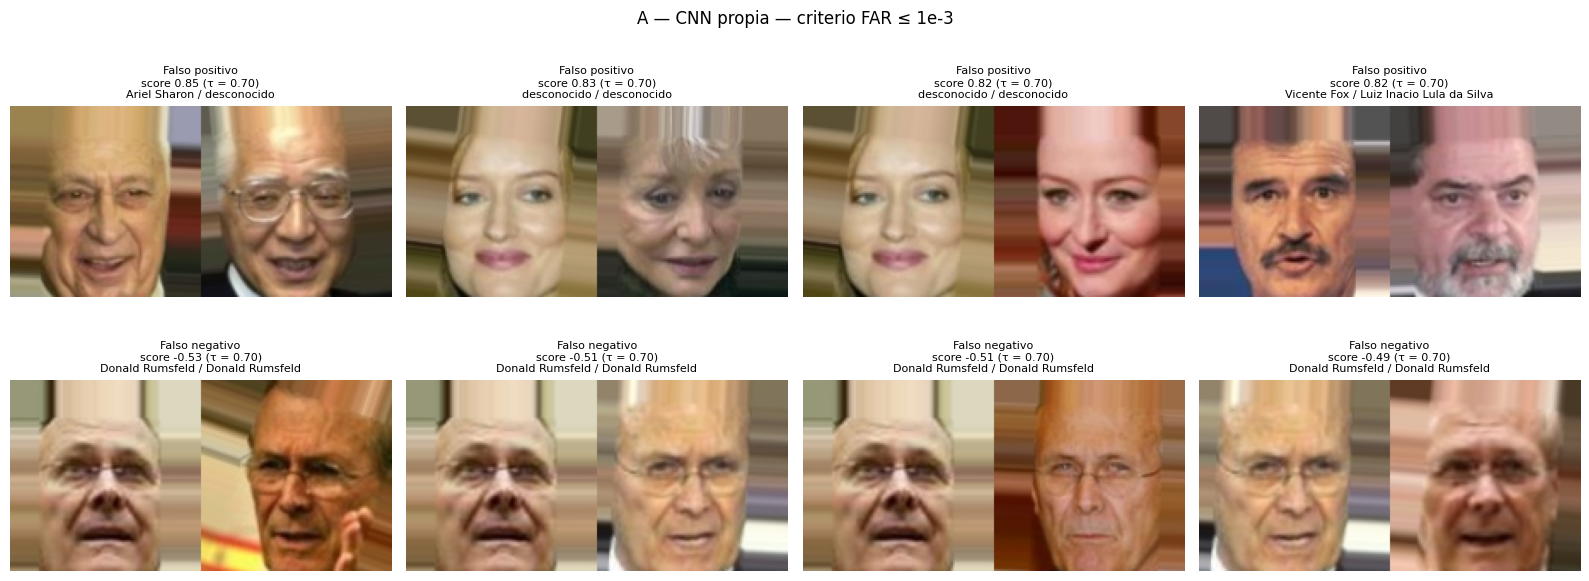

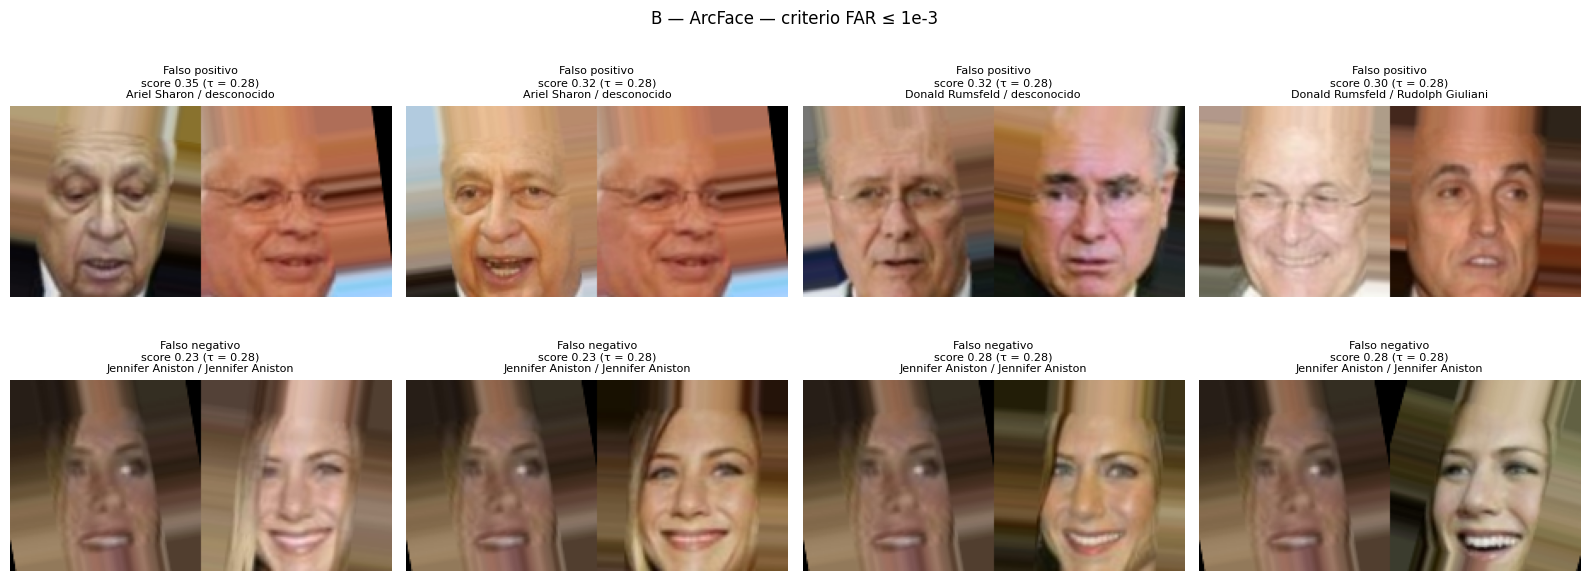

In [ ]:
imgs_ot = np.concatenate([caras_rgb[m_open_te], caras_unk_rgb[unk_te]])
nom_ot = np.array([nombres[v] for v in y[m_open_te]] + ["desconocido"] * int(unk_te.sum()))

def pares_extremos(E, labs, n=4):
    sims = E @ E.T
    i, j = np.triu_indices(len(E), 1)
    s = sims[i, j]; misma = labs[i] == labs[j]
    ig, ii = np.where(misma)[0], np.where(~misma)[0]
    fp = ii[np.argsort(-s[ii])[:n]]          # distintas personas, mayor similitud
    fn = ig[np.argsort(s[ig])[:n]]           # misma persona, menor similitud
    return [(i[p], j[p], s[p]) for p in fp], [(i[p], j[p], s[p]) for p in fn]

def mostrar_pares(fila_pares, titulo, axs, tau):
    for ax, (a, b, s) in zip(axs, fila_pares):
        ax.imshow(np.hstack([imgs_ot[a], imgs_ot[b]])); ax.axis("off")
        ax.set_title(f"{titulo}\nscore {s:.2f} (τ = {tau:.2f})\n{nom_ot[a]} / {nom_ot[b]}", fontsize=8)

for nombre, (E, Eu) in EMB.items():
    tau = UMBRALES[nombre][CRITERIO]
    fp, fn = pares_extremos(np.concatenate([E[m_open_te], Eu[unk_te]]), labs_ot)
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
    mostrar_pares(fp, "Falso positivo", axes[0], tau)
    mostrar_pares(fn, "Falso negativo", axes[1], tau)
    fig.suptitle(f"{nombre} — criterio {CRITERIO}", fontsize=12)
    plt.tight_layout(); plt.show()

**Hipótesis sobre las causas de los errores** (se muestran los casos más extremos entre miles de pares; con ArcFace los errores son muy pocos y quedan cerca del umbral):

- **Falsos positivos por parecido real.** Casi todos los pares confundidos son de personas del mismo sexo, edad y aspecto general: dos mujeres rubias de piel clara, o varios hombres mayores con frente despejada y canas (Sharon, Rumsfeld, Giuliani). Fox y Lula, ambos con bigote y pelo oscuro, es otro ejemplo. La CNN los acepta con scores altos (0,82–0,85, bien por encima de τ = 0,70), lo que indica que sus embeddings capturan rasgos globales (sexo, edad, peinado) y no los detalles que distinguen a una persona. Con ArcFace los falsos positivos más fuertes puntúan 0,30–0,35 contra τ = 0,28: son errores marginales.
- **Falsos negativos por pose, iluminación y calidad.** Con la CNN, las fotos de Rumsfeld difieren en pose, expresión, edad e iluminación, y el score llega a ser negativo (−0,5): la red no es invariante a esos cambios, algo esperable con ~1.450 imágenes de entrenamiento. Con ArcFace, los cuatro falsos negativos más claros comparten la misma foto de Jennifer Aniston, subexpuesta y de baja calidad, comparada con fotos nítidas y sonrientes; una sola imagen de mala calidad explica todos los casos.
- **Baja resolución.** Las imágenes de LFW son chicas (125×94) y la cara se agranda a 112×112, por lo que se ven suavizadas; además, el relleno de bordes que agregamos antes de detectar deja franjas horizontales en los extremos. Esto limita el detalle disponible para los dos modelos, sobre todo en fotos ya oscuras o borrosas.

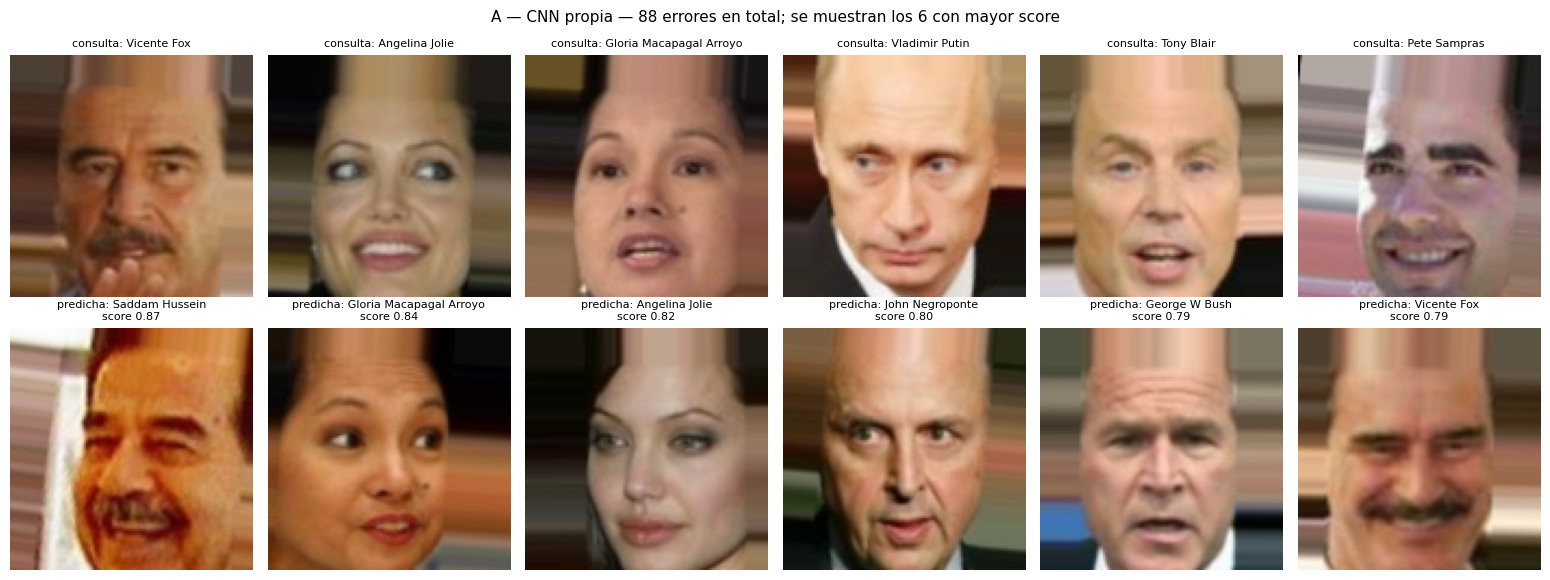

B — ArcFace: sin errores de identificación


In [ ]:
idx_q_all, idx_g_all = np.where(m_cons)[0], np.where(m_gal5)[0]

for nombre, (E, _) in EMB.items():
    mal = np.where(pred_ident[nombre] != y_q)[0]
    if len(mal) == 0:
        print(f"{nombre}: sin errores de identificación"); continue
    mal = mal[np.argsort(-S_ident[nombre].max(axis=1)[mal])][:6]
    fig, axes = plt.subplots(2, len(mal), figsize=(2.6 * len(mal), 6), squeeze=False)
    for c, q in enumerate(mal):
        gi = idx_g_all[(E[idx_q_all[q]] @ E[m_gal5].T).argmax()]
        axes[0, c].imshow(caras_rgb[idx_q_all[q]]); axes[0, c].axis("off")
        axes[0, c].set_title(f"consulta: {nombres[y_q[q]]}", fontsize=8)
        axes[1, c].imshow(caras_rgb[gi]); axes[1, c].axis("off")
        axes[1, c].set_title(f"predicha: {nombres[pred_ident[nombre][q]]}\nscore {S_ident[nombre][q].max():.2f}", fontsize=8)
    fig.suptitle(f"{nombre} — {int((pred_ident[nombre] != y_q).sum())} errores en total; se muestran los 6 con mayor score", fontsize=11)
    plt.tight_layout(); plt.show()

In [ ]:
MUJERES = [
    "Angelina Jolie", "Gloria Macapagal Arroyo", "Jennifer Aniston",
    "Jennifer Capriati", "Jennifer Lopez", "Laura Bush", "Lindsay Davenport",
    "Megawati Sukarnoputri", "Naomi Watts", "Serena Williams", "Winona Ryder",
]       # la misma lista de la notebook 1
print("Nombres de MUJERES que no están en el closed-set (revisar):", sorted(set(MUJERES) - set(df["persona"])))
mujer = df["persona"].isin(MUJERES).values
print(f"Mujeres: {mujer[m_cons].mean() * 100:.1f}% de las consultas de test ({mujer[m_cons].sum()} de {m_cons.sum()})")

def far_por_genero(E, labs, es_mujer, tau):
    sims = E @ E.T
    i, j = np.triu_indices(len(E), 1)
    s = sims[i, j]; imp = labs[i] != labs[j]
    mm, hh = es_mujer[i] & es_mujer[j], ~es_mujer[i] & ~es_mujer[j]
    return {"mujer–mujer": (s[imp & mm] >= tau).mean(), "hombre–hombre": (s[imp & hh] >= tau).mean(),
            "mujer–hombre": (s[imp & ~mm & ~hh] >= tau).mean()}

filas = []
for nombre, (E, _) in EMB.items():
    tau = UMBRALES[nombre][CRITERIO]
    err = pred_ident[nombre] != y_q
    fila = {"modelo": nombre,
            "error Top-1, mujeres": err[mujer[m_cons]].mean(), "error Top-1, hombres": err[~mujer[m_cons]].mean()}
    fila.update({f"FAR {k}": v for k, v in far_por_genero(E[m_cons], y_q, mujer[m_cons], tau).items()})
    filas.append(fila)
display(pd.DataFrame(filas).set_index("modelo").round(4))

Nombres de MUJERES que no están en el closed-set (revisar): []
Mujeres: 11.4% de las consultas de test (51 de 446)


,"error Top-1, mujeres","error Top-1, hombres",FAR mujer–mujer,FAR hombre–hombre,FAR mujer–hombre
modelo,,,,,
A — CNN propia,0.1961,0.1975,0.0043,0.0014,0.0
B — ArcFace,0.0000,0.0000,0.0000,0.0002,0.0


**Errores de identificación de la CNN.** Los errores con mayor score son confusiones entre personas con aspecto parecido: Fox con Saddam Hussein (0,87, ambos con bigote y pelo oscuro), Angelina Jolie con Gloria Arroyo (y viceversa, 0,84 y 0,82, ambas mujeres de pelo oscuro), Putin con Negroponte (0,80) y Blair con Bush (0,79), todos hombres de piel clara fotografiados de frente. Es consistente con la hipótesis de parecido real: la CNN se apoya en rasgos globales (sexo, edad, peinado, vello facial) más que en rasgos propios de cada persona. ArcFace no comete errores de identificación.

**Errores por género.** Las mujeres son solo el 11,4% de las consultas de test (51 de 446), reflejo del desbalance del dataset. Con la CNN, el error de identificación es prácticamente igual en mujeres (19,6%) y en hombres (19,8%), por lo que no observamos una brecha de género en la identificación. En los falsos positivos por pares, sí hay una diferencia: el FAR entre pares de mujeres (0,43%) es unas tres veces el de pares de hombres (0,14%), mientras que entre pares mixtos no hay ningún falso positivo; es decir, los errores ocurren entre personas del mismo género. Hay que interpretar estas diferencias con cuidado, porque hay muy pocas mujeres (11 identidades) y pocos errores (≈10 en mujeres), y no son estadísticamente concluyentes. ArcFace casi no comete errores en ningún grupo (FAR de 0,02% solo en pares de hombres). Que los falsos positivos se concentren dentro del mismo género es coherente con los reportes de NIST sobre diferencias demográficas en reconocimiento facial, y es otra razón para evaluar el sistema por grupos antes de usarlo.

### **f) Costo computacional**

Tamaño del modelo (archivo y parámetros), dimensión del embedding y **tiempo de inferencia por rostro en CPU** (cara ya alineada de 112×112, una por vez, como en la app; incluye el preprocesamiento de cada modelo). No incluye detección ni alineación, que son iguales para los dos. Los tiempos dependen de la CPU de esta sesión.

In [ ]:
def ms_por_cara(fn, n=100, calentamiento=10):
    for _ in range(calentamiento):
        fn()
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000

modelo_A_cpu = copy.deepcopy(modelo_A).cpu().eval()
cara_rgb, cara_bgr = caras_rgb[0], caras[0]

def inferir_A():
    with torch.no_grad():
        modelo_A_cpu.embedding(a_tensor(cara_rgb).unsqueeze(0))

n_params_A = sum(p.numel() for nom, p in modelo_A.named_parameters() if not nom.startswith("clasif"))   # sin la cabeza de clasificación
costo = {
    "A — CNN propia": {"Tamaño del archivo (MB)": os.path.getsize(f"{BASE}/cnn_softmax.pt") / 1e6,
                       "Parámetros": n_params_A, "Dimensión del embedding": E_A.shape[1],
                       "CPU (ms por cara)": ms_por_cara(inferir_A)},
    "B — ArcFace": {"Tamaño del archivo (MB)": tam_B, "Parámetros": n_params_B, "Dimensión del embedding": E_B.shape[1],
                    "CPU (ms por cara)": ms_por_cara(lambda: modelo_B.get_feat([cara_bgr]))},
}
print(f"CPUs de la sesión: {os.cpu_count()}")
display(pd.DataFrame(costo).T.style.format({"Tamaño del archivo (MB)": "{:.1f}", "Parámetros": "{:,.0f}",
                                            "Dimensión del embedding": "{:.0f}", "CPU (ms por cara)": "{:.2f}"}))

CPUs de la sesión: 2


,Tamaño del archivo (MB),Parámetros,Dimensión del embedding,CPU (ms por cara)
A — CNN propia,9.6,"2,387,040",128,70.54
B — ArcFace,174.4,"43,590,976",512,406.59


**Interpretación del costo computacional** (medido en una sesión de Colab con 2 CPUs, una cara por vez, incluyendo el preprocesamiento de cada modelo; sin contar la detección ni la alineación, que son las mismas para ambos):

- **ArcFace es unas 18 veces más grande** que la CNN propia, tanto en archivo (174,4 MB contra 9,6 MB) como en parámetros (43,6 M contra 2,4 M), y su embedding es 4 veces más largo (512 contra 128 dimensiones), lo que también aumenta el espacio de la base de datos por cada cara registrada.
- **En tiempo de inferencia ArcFace es unas 5,8 veces más lento** (≈407 ms contra ≈71 ms por cara en CPU). Aun así, ≈0,4 s por cara es aceptable para una app que registra y reconoce imágenes una a una; sería un límite para video en tiempo real sin GPU o con una CPU más lenta. Los tiempos dependen de la máquina y deberían medirse de nuevo en el servidor donde corra la app.
- La CNN propia es mucho más liviana, pero como vimos en las demás evaluaciones, su calidad no alcanza para la app, así que el ahorro en costo no compensa la diferencia en desempeño.

## **Comparación y elección final**


Tabla comparativa con todas las métricas anteriores (test; el umbral se calibró en validación). Las métricas open-set usan el criterio indicado en `CRITERIO`.

In [ ]:
MODELO_ELEGIDO = "B — ArcFace"

filas = {}
for nombre in EMB:
    v, idn = res_verif[nombre], res_ident[nombre]
    o = RES_OPEN[nombre][CRITERIO]
    filas[nombre] = {
        "Verificación — AUC": v["AUC"], "Verificación — EER": v["EER"],
        "Verificación — TAR@FAR=1e-2": v["TAR@FAR=1e-2"], "Verificación — TAR@FAR=1e-3": v["TAR@FAR=1e-3"],
        "Identificación — Top-1": idn["Top-1"], "Identificación — Top-5": idn["Top-5"], "Identificación — F1 macro": idn["F1 (macro)"],
        f"Open-set ({CRITERIO}) — τ": UMBRALES[nombre][CRITERIO],
        f"Open-set ({CRITERIO}) — id. correcta": o["id. correcta"],
        f"Open-set ({CRITERIO}) — desconocidos rechazados": o["desconocidos rechazados"],
        "Clustering — silhouette": res_clust[nombre]["Silhouette (identidades reales)"],
        "Clustering — ARI": res_clust[nombre]["ARI (K-Means)"], "Clustering — NMI": res_clust[nombre]["NMI (K-Means)"],
        "Costo — tamaño (MB)": costo[nombre]["Tamaño del archivo (MB)"], "Costo — parámetros": costo[nombre]["Parámetros"],
        "Costo — dimensión": costo[nombre]["Dimensión del embedding"], "Costo — CPU (ms/cara)": costo[nombre]["CPU (ms por cara)"],
    }
def formato(fila, v):
    if "parámetros" in fila: return f"{v:,.0f}"
    if "dimensión" in fila: return f"{v:.0f}"
    if "(MB)" in fila or "ms/cara" in fila: return f"{v:.1f}" if "(MB)" in fila else f"{v:.2f}"
    return f"{v:.4f}"
tabla_comp = pd.DataFrame(filas)
display(pd.DataFrame({n: {f: formato(f, v) for f, v in col.items()} for n, col in tabla_comp.items()}))

,A — CNN propia,B — ArcFace
Verificación — AUC,0.8890,1.0000
Verificación — EER,0.1891,0.0001
Verificación — TAR@FAR=1e-2,0.3196,1.0000
Verificación — TAR@FAR=1e-3,0.1100,0.9999
Identificación — Top-1,0.8027,1.0000
Identificación — Top-5,0.9619,1.0000
Identificación — F1 macro,0.7587,1.0000
Open-set (FAR ≤ 1e-3) — τ,0.7045,0.2751
Open-set (FAR ≤ 1e-3) — id. correcta,0.6637,1.0000
Open-set (FAR ≤ 1e-3) — desconocidos rechazados,0.7363,0.9502


## **Conclusión y elección del modelo**

**Elegimos el Modelo B (ArcFace preentrenado de InsightFace, `w600k_r50.onnx`) para la app.**

| Criterio | A — CNN propia | B — ArcFace |
|---|---|---|
| Verificación: EER (test) | 18,9% | **0,01%** |
| Verificación: TAR@FAR=1e-3 | 11,0% | **99,99%** |
| Identificación: Top-1 / Top-5 | 80,3% / 96,2% | **100% / 100%** |
| Open-set con umbral FAR ≤ 1e-3: conocidos bien identificados / desconocidos rechazados | 66,4% / 73,6% | **100% / 95,0%** |
| Clustering: silhouette / ARI | 0,26 / 0,58 | **0,61 / 1,00** |
| Tamaño / parámetros | **9,6 MB / 2,4 M** | 174,4 MB / 43,6 M |
| Tiempo por cara en CPU | **71 ms** | 407 ms |

**Desempeño.** ArcFace es mejor en todas las métricas de calidad y la diferencia es muy grande, sobre todo donde importa para la app: con pocos falsos positivos (FAR = 1e-3) reconoce prácticamente todos los pares de la misma persona, mientras que la CNN propia reconoce solo el 11%. La CNN no logra un umbral utilizable: para rechazar desconocidos tiene que dejar de reconocer a muchas personas registradas.

**Por qué la CNN propia rinde menos.** La CNN tiene un accuracy alto (95,8%) al clasificar las 43 personas con las que se entrenó, pero un EER de 24,0% en validación (18,9% en test) con personas nuevas: aprendió a distinguir esas 43 identidades y no rasgos faciales generales. El factor limitante es la **cantidad de identidades de entrenamiento** (43 personas y ~1.450 imágenes, contra 600.000 identidades de WebFace600K). El experimento con ArcFace loss, que es la técnica con la que se entrenó el modelo preentrenado, no mejoró el resultado (EER en validación 23,5% contra 24,0%, dentro de la variabilidad entre corridas), lo que confirma que el problema son los datos y no la función de pérdida. Los errores de la CNN son además de "parecido real": confunde personas del mismo sexo, edad y aspecto general, y no es robusta a cambios de pose e iluminación.

**Costo.** ArcFace es unas 18 veces más grande y 5,8 veces más lento por cara. Con ≈0,4 s por cara en una CPU de 2 núcleos es aceptable para una app que registra y reconoce imágenes una por una. La CNN es más liviana, pero ese ahorro no compensa la diferencia de calidad.

**Licencia.** Los modelos preentrenados de InsightFace son para **uso no comercial / investigación**: es adecuado para este trabajo académico, pero habría que cambiar de modelo o conseguir una licencia para un uso comercial. La CNN propia no tiene esa restricción, aunque el dataset (LFW) tiene sus propias condiciones de uso.

**Facilidad de integración.** ArcFace ya viene en formato ONNX (la opción recomendada por el enunciado), con el detector `det_10g.onnx` en el mismo paquete, y se carga con `onnxruntime` sin depender de código de clases. Usar la CNN propia requeriría exportarla a ONNX y replicar en la app su preprocesamiento (RGB y normalización con la media y el desvío del train).

**Umbral para la app.** Para el Modelo B proponemos `SIMILARITY_THRESHOLD = 0,328` (calibrado en validación para aceptar como mucho el 1% de los desconocidos). En test, con ese umbral, identifica bien al 100% de las personas registradas y rechaza al 99,5% de los desconocidos.

**Limitaciones y precauciones.**
- Los resultados de ArcFace pueden ser **optimistas**: WebFace600K también se armó con fotos de personas públicas de internet y es posible que algunas de nuestras personas estuvieran en su entrenamiento. Además, LFW tiene fotos mayormente frontales y de buena calidad, así que el desempeño en condiciones reales sería menor.
- El dataset tiene muchos más hombres que mujeres (las mujeres son el 11% de las consultas de test). Con la CNN los falsos positivos se concentran entre personas del mismo género; con ArcFace casi no hay errores, pero con tan pocas mujeres no se puede concluir que el sistema funcione igual para todos los grupos.
- El umbral de 1% de falsos positivos se calibró con 195 desconocidos, por lo que su precisión es limitada.

In [ ]:
os.makedirs(f"{BASE}/modelos", exist_ok=True)
RUTA_DET = os.path.expanduser("~/.insightface/models/buffalo_l/det_10g.onnx")
for ruta in (RUTA_B, RUTA_DET):
    shutil.copy(ruta, f"{BASE}/modelos/")
    print("Copiado a Drive:", f"modelos/{os.path.basename(ruta)}", f"({os.path.getsize(ruta) / 1e6:.0f} MB)")

# Verificación con onnxruntime y el preprocesamiento de la app
sesion = ort.InferenceSession(f"{BASE}/modelos/w600k_r50.onnx", providers=["CPUExecutionProvider"])
entrada = sesion.get_inputs()[0].name
cos = []
for i in range(20):
    blob = cv2.dnn.blobFromImage(caras[i], 1 / 127.5, (112, 112), (127.5, 127.5, 127.5), swapRB=True)
    e = sesion.run(None, {entrada: blob})[0][0]
    e = e / np.linalg.norm(e)
    cos.append(float(e @ E_B[i]))
print(f"Entrada del modelo: {sesion.get_inputs()[0].shape} | salida: {sesion.get_outputs()[0].shape}")
print(f"Coseno entre el embedding de onnxruntime (preprocesamiento de la app) y el usado en la evaluación: mín {min(cos):.5f}")

# Umbral calibrado para el .env
CRITERIO_APP = "FPIR ≤ 1%"
tau_final = UMBRALES[MODELO_ELEGIDO][CRITERIO_APP]
config = {"MODEL_NAME": "w600k_r50.onnx", "SIMILARITY_METRIC": "cosine",
         "SIMILARITY_THRESHOLD": round(tau_final, 3), "criterio": CRITERIO_APP,
          "calibrado_con": "consultas de validación (closed-set val + 195 desconocidos de val), galería de 5 imágenes por persona"}
with open(f"{BASE}/umbral_calibrado.json", "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print("\nConfiguración para el .env:", json.dumps(config, ensure_ascii=False))

Copiado a Drive: modelos/w600k_r50.onnx (174 MB)
Copiado a Drive: modelos/det_10g.onnx (17 MB)
Entrada del modelo: ['None', 3, 112, 112] | salida: [1, 512]
Coseno entre el embedding de onnxruntime (preprocesamiento de la app) y el usado en la evaluación: mín 1.00000

Configuración para el .env: {"MODEL_NAME": "w600k_r50.onnx", "SIMILARITY_METRIC": "cosine", "SIMILARITY_THRESHOLD": 0.328, "criterio": "FPIR ≤ 1%", "calibrado_con": "consultas de validación (closed-set val + 195 desconocidos de val), galería de 5 imágenes por persona"}
